# Klasifikasi Penggunaan dan Tutupan Lahan LULC (Land Use / Land Cover) Jawa Timur
## Sistem Informasi Geografis berbasis Analisis Spasial Penggunaan Lahan dan Kebijakan

**Mata kuliah:** Proyek Sains Data (UTS) &nbsp;|&nbsp; **Citra:** Sentinel-2 L2A &nbsp;|&nbsp; **Data referensi:** 360 poligon (6 kelas × 60 poligon)

Alur notebook ini:

1. Data Understanding (tujuan, wilayah, acuan klasifikasi Indonesia, kelas, band Sentinel-2A)
2. Data Collection (shapefile poligon → statistik zonal per poligon dari citra Sentinel-2)
3. Deskripsi fitur dan rumusnya
4. Eksplorasi Data (EDA)
5. Pembagian data training dan testing
6. **Perbandingan banyak model** (KNN, SVM, Random Forest, Extra Trees, Gradient Boosting, dst.) + tuning + eksperimen
7. Prediksi raster Jawa Timur dan peta interaktif (Folium + Google Satellite)
8. Ekspor ke aplikasi **Streamlit**
9. Kesimpulan

> **Perubahan utama dari tugas sebelumnya:** unit sampel adalah **poligon** (bukan piksel). Setiap poligon diringkas menjadi **satu baris data** (median piksel di dalam poligon), sehingga tiap kelas tepat 60 data dan seimbang.

## 1. Data Understanding

### 1.1 Latar Belakang
Informasi penggunaan dan tutupan lahan (*Land Use / Land Cover*, LULC) dibutuhkan untuk perencanaan tata ruang, pengendalian alih fungsi lahan sawah, perlindungan ekosistem pesisir (mangrove), dan pengelolaan sumber daya air. Pemetaan manual mahal dan lambat. Citra **Sentinel-2** (gratis, resolusi hingga 10 m, revisit beberapa hari) yang dikombinasikan dengan *machine learning* memungkinkan klasifikasi lahan otomatis. Pada tugas sebelumnya klasifikasi hanya dua kelas (sawah vs non-sawah); pada UTS ini diperluas menjadi **6 kelas** dan **beberapa algoritma dibandingkan**, lalu hasilnya dipublikasikan sebagai sistem informasi berbasis Streamlit.

### 1.2 Tujuan Analisis *Land Use and Land Classification*
1. Mengklasifikasikan LULC Provinsi Jawa Timur ke dalam 6 kelas (sawah, bangunan, mangrove, lahan hijau, perairan terbuka/laut, danau/ranu) berdasarkan reflektansi band Sentinel-2 dan indeks spektral.
2. Mengidentifikasi karakteristik spektral tiap kelas (band/indeks mana yang paling membedakan).
3. **Membandingkan beberapa algoritma klasifikasi** dan memilih model dengan akurasi terbaik secara objektif (validasi silang + data uji terpisah).
4. Mengeksperimenkan kombinasi fitur, rasio data latih/uji, dan *hyperparameter*.
5. Menyajikan hasil sebagai peta interaktif di atas citra satelit Google Maps (Folium/Leaflet) dan sistem informasi berbasis Streamlit.
6. Menurunkan **implikasi kebijakan** (tata ruang, perlindungan lahan sawah, konservasi mangrove) dari statistik luas hasil klasifikasi.

### 1.3 Wilayah Studi
Provinsi Jawa Timur (± 111,0°–114,65° BT; 6,75°–8,85° LS): pegunungan dan taman nasional (Bromo-Tengger-Semeru, Alas Purwo), dataran sawah, kawasan perkotaan padat (Surabaya–Sidoarjo–Gresik), pesisir bermangrove, danau/ranu/waduk, Laut Jawa, Selat Madura, dan Samudra Hindia.

### 1.4 Acuan Klasifikasi Lahan di Indonesia
Klasifikasi lahan di Indonesia diacu pada **SNI 7645 tentang Klasifikasi Penutup Lahan** (SNI 7645-1:2014 untuk skala kecil–menengah dan SNI 7645-2:2010 untuk skala besar) serta **klasifikasi penutupan lahan KLHK** (sekitar 23 kelas, misalnya hutan lahan kering, hutan mangrove, sawah, tambak, permukiman, lahan terbuka, tubuh air). Pada UTS ini 6 kelas dipetakan (digeneralisasi) ke kategori acuan tersebut:

| Kelas penelitian | Kategori acuan SNI 7645 / KLHK (diadaptasi) | Catatan |
|---|---|---|
| Sawah | Daerah pertanian → Sawah | Lahan pertanian basah, pola tanam padi |
| Bangunan | Permukiman dan lahan bukan pertanian | Perkotaan, industri, infrastruktur |
| Mangrove | Hutan mangrove (primer/sekunder) | Vegetasi pesisir pasang-surut |
| Lahan Hijau | Gabungan hutan lahan kering, semak/belukar, kebun/perkebunan, tegalan | Vegetasi non-sawah dan non-mangrove |
| Perairan Terbuka (Laut) | Perairan → tubuh air laut | Laut Jawa, Selat Madura, Samudra Hindia |
| Danau | Perairan → tubuh air tawar (danau/ranu/waduk) | Contoh: Ranu Pani, Ranu Kumbolo, Ranu Regulo |

> Kategori di atas adalah penyederhanaan untuk keperluan tugas. Untuk laporan resmi, rujuk dokumen SNI/KLHK yang diwajibkan dosen.

### 1.5 Kelas dan Jumlah Data
Data referensi berupa shapefile poligon (`input.shp` per kelas, CRS WGS84/EPSG:4326). **Satu poligon = satu sampel** (nilai median piksel di dalam poligon).

| ID | Kelas | Folder shapefile | Jumlah poligon (sampel) |
|---|---|---|---|
| 1 | Sawah | `sawah` | 60 |
| 2 | Bangunan | `bangunan` | 60 |
| 3 | Mangrove | `mangrove` | 60 |
| 4 | Lahan Hijau | `lahan_hijau` | 60 |
| 5 | Perairan Terbuka (Laut) | `laut` | 60 |
| 6 | Danau | `danau` | 60 |
| | **Total** | | **360 sampel, 6 kelas (seimbang)** |

Dengan pembagian *stratified* 80:20 diperoleh **288 data training (48 per kelas)** dan **72 data testing (12 per kelas)**.

### 1.6 Band pada Sentinel-2
Sentinel-2 membawa sensor MSI (*MultiSpectral Instrument*) dengan 13 band (cahaya tampak sampai SWIR), lebar sapuan 290 km, resolusi 10/20/60 m. Sentinel-2A (diluncurkan 2015) dan Sentinel-2B (2017) membawa sensor MSI yang identik sehingga susunan band-nya sama. Produk yang dipakai: **Level-2A** (reflektansi permukaan, sudah koreksi atmosfer) dari Copernicus Data Space Ecosystem.

| Band | Nama | Panjang gelombang tengah (nm) | Resolusi | Kegunaan utama | Dipakai? |
|---|---|---|---|---|---|
| B1 | Coastal aerosol | 443 | 60 m | Koreksi aerosol, studi perairan pesisir | Tidak |
| B2 | Blue | 492 | 10 m | Penetrasi air, pembeda tanah/vegetasi/bangunan | **Ya** |
| B3 | Green | 560 | 10 m | Puncak pantulan vegetasi, indeks air | **Ya** |
| B4 | Red | 665 | 10 m | Penyerapan klorofil, pembeda vegetasi dan lahan terbuka | **Ya** |
| B5 | Red Edge 1 | 704 | 20 m | Kandungan klorofil | **Ya** |
| B6 | Red Edge 2 | 740 | 20 m | Struktur kanopi | **Ya** |
| B7 | Red Edge 3 | 783 | 20 m | Struktur kanopi | **Ya** |
| B8 | NIR | 833 | 10 m | Biomassa vegetasi, pemisah daratan dan air | **Ya** |
| B8A | Narrow NIR | 865 | 20 m | Vegetasi, kadar air tanaman | **Ya** |
| B9 | Water vapour | 945 | 60 m | Koreksi uap air | Tidak |
| B10 | SWIR-Cirrus | 1374 | 60 m | Deteksi awan cirrus (tidak ada di L2A) | Tidak |
| B11 | SWIR 1 | 1614 | 20 m | Kelembapan vegetasi/tanah, area terbangun, pembeda air | **Ya** |
| B12 | SWIR 2 | 2202 | 20 m | Tanah terbuka, area terbangun, lahan terbakar | **Ya** |

B1, B9, B10 tidak dipakai karena untuk koreksi atmosfer/deteksi awan, bukan pembeda jenis lahan.

### 1.7 Alur Kerja
```
Shapefile poligon (6 kelas x 60) -> komposit median Sentinel-2 L2A (masking awan SCL)
  -> statistik zonal (median piksel dalam poligon) -> 10 band + 8 indeks = 18 fitur (CSV)
  -> EDA -> split stratified 80:20 -> perbandingan >= 10 model (CV berulang)
  -> tuning model teratas -> evaluasi data uji -> prediksi raster Jawa Timur
  -> peta Folium (Google Satellite) -> aplikasi Streamlit
```

## 2. Data Collection
### 2.1 Persiapan Lingkungan dan Konfigurasi

Citra diambil dari **Copernicus Data Space Ecosystem (CDSE)** melalui **Sentinel Hub Process API** (gratis dengan kuota bulanan). Pemrosesan (masking awan + komposit median) berlangsung di server Copernicus sehingga hanya nilai piksel yang diunduh.

**Membuat kredensial (sekali saja):**
1. Daftar di <https://dataspace.copernicus.eu>, login.
2. Buka <https://shapps.dataspace.copernicus.eu/dashboard/#/account/settings> → **OAuth clients** → **Create new**.
3. Simpan **Client ID** dan **Client Secret** (secret hanya tampil sekali).

In [92]:
# Google Colab: jalankan sekali. (xgboost & lightgbm sudah ada di Colab; geopandas/sentinelhub perlu dipasang)
!pip install -q geopandas shapely sentinelhub folium

In [93]:
import os, io, math, time, json, getpass, warnings, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import geopandas as gpd
import folium
from folium.raster_layers import ImageOverlay
from shapely import contains_xy
from PIL import Image
from IPython.display import display, Markdown
import sklearn
from sentinelhub import (SHConfig, SentinelHubRequest, DataCollection, BBox, CRS,
                         MimeType)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_score, GridSearchCV)
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, make_scorer,
                             classification_report, confusion_matrix)
from sklearn.inspection import permutation_importance

# ----------------- KONFIGURASI (SESUAIKAN) -----------------
import sys
IN_COLAB = "google.colab" in sys.modules
SIMPAN_KE_DRIVE = True             # True: cache/hasil disimpan ke Google Drive (aman jika runtime Colab terputus)
FOLDER_DRIVE = "UTS_LULC_Jatim"    # nama folder kerja di Google Drive
TANGGAL_MULAI, TANGGAL_AKHIR = "2025-01-01", "2025-12-31"
MAX_CLOUD = 30                     # maks. % awan per scene
HANYA_SENTINEL_2A = False          # True: hanya citra Sentinel-2A
SEED = 42
UKURAN_TEST = 0.20
MAKS_PX_POLIGON = 120              # grid maks. per sisi saat mengekstrak 1 poligon
ULANGI_EKSTRAKSI = False           # True: paksa ambil ulang dari Copernicus
# ------------------------------------------------------------

if IN_COLAB and SIMPAN_KE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = f"/content/drive/MyDrive/{FOLDER_DRIVE}"
else:
    BASE = "./uts_lulc"
os.makedirs(BASE, exist_ok=True)
DATA_DIR    = os.path.join(BASE, "data")             # shapefile hasil ekstrak zip
CSV_DATASET = os.path.join(BASE, "dataset_polygon_sentinel2_jatim.csv")
FILE_PETA   = os.path.join(BASE, "label_peta.npz")
OUT_DIR     = os.path.join(BASE, "app_data")         # keluaran untuk Streamlit
for d in (DATA_DIR, OUT_DIR): os.makedirs(d, exist_ok=True)
print("Folder kerja:", BASE)

KELAS = {
    1: dict(nama="Sawah",                   folder=("sawah",),            warna="#FFD92F"),
    2: dict(nama="Bangunan",                folder=("bangunan",),         warna="#E41A1C"),
    3: dict(nama="Mangrove",                folder=("mangrove",),         warna="#8E44AD"),
    4: dict(nama="Lahan Hijau",             folder=("lahan_hijau",),      warna="#2E7D32"),
    5: dict(nama="Perairan Terbuka (Laut)", folder=("laut", "lautan"),    warna="#0D47A1"),
    6: dict(nama="Danau",                   folder=("danau",),            warna="#4FC3F7"),
}
NAMA_KELAS  = [v["nama"] for v in KELAS.values()]
WARNA_KELAS = {v["nama"]: v["warna"] for v in KELAS.values()}
print("Kelas:", NAMA_KELAS, "| scikit-learn", sklearn.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder kerja: /content/drive/MyDrive/UTS_LULC_Jatim
Kelas: ['Sawah', 'Bangunan', 'Mangrove', 'Lahan Hijau', 'Perairan Terbuka (Laut)', 'Danau'] | scikit-learn 1.6.1


### Unggah shapefile (zip)
Jalankan sel di bawah, lalu pilih ke-6 file zip (`sawah.zip`, `bangunan.zip`, `mangrove.zip`, `lahan_hijau.zip`, `laut.zip`, `danau.zip`). Tiap zip berisi `input.shp/.shx/.dbf/.prj` dan otomatis diekstrak ke `data/<nama_kelas>/`. Jika sudah pernah diunggah (dan folder kerja di Drive), langkah ini otomatis dilewati. Alternatif: taruh zip di Drive lalu isi `ZIP_DI_DRIVE` dengan path foldernya.

In [95]:
import zipfile, glob, shutil

ZIP_DI_DRIVE = ""      # contoh: "/content/drive/MyDrive/shapefile_uts" (kosongkan untuk unggah manual)

# kata kunci pada nama zip -> nama folder tujuan
KUNCI_KELAS = {"sawah": "sawah", "bangunan": "bangunan", "mangrove": "mangrove",
               "hijau": "lahan_hijau", "laut": "laut", "danau": "danau"}
EKSTENSI_SHP = (".shp", ".shx", ".dbf", ".prj", ".cpg", ".sbn", ".sbx", ".qmd")

def kelas_belum_ada():
    return [d for d in KUNCI_KELAS.values() if not glob.glob(os.path.join(DATA_DIR, d, "*.shp"))]

if not kelas_belum_ada():
    print("Shapefile sudah tersedia di", DATA_DIR)
else:
    shutil.rmtree(DATA_DIR, ignore_errors=True); os.makedirs(DATA_DIR, exist_ok=True)   # bersihkan sisa ekstrak yang salah
    if ZIP_DI_DRIVE:
        zips = glob.glob(os.path.join(ZIP_DI_DRIVE, "*.zip"))
    else:
        from google.colab import files
        up = files.upload(); zips = list(up.keys())

    for z in zips:
        nama = os.path.splitext(os.path.basename(z))[0].lower()
        target = next((v for k, v in KUNCI_KELAS.items() if k in nama), None)
        if target is None:
            print(f"DILEWATI (nama tidak dikenali): {z}"); continue
        tujuan = os.path.join(DATA_DIR, target); os.makedirs(tujuan, exist_ok=True)
        n_shp = 0
        with zipfile.ZipFile(z) as zf:
            for info in zf.infolist():
                if info.is_dir() or not info.filename.lower().endswith(EKSTENSI_SHP): continue
                with zf.open(info) as src, open(os.path.join(tujuan, os.path.basename(info.filename)), "wb") as dst:
                    shutil.copyfileobj(src, dst)
                n_shp += info.filename.lower().endswith(".shp")
        print(f"{z} -> data/{target}/  ({n_shp} file .shp)")

    kurang = kelas_belum_ada()
    assert not kurang, f"Kelas ini masih belum ada file .shp-nya: {kurang}. Periksa isi zip-nya."
    print("Semua 6 kelas lengkap.")

Saving bangunan.zip to bangunan (2).zip
Saving danau.zip to danau (2).zip
Saving lahan_hijau.zip to lahan_hijau (2).zip
Saving laut.zip to laut (3).zip
Saving mangrove.zip to mangrove (2).zip
Saving sawah.zip to sawah (2).zip
bangunan (2).zip -> data/bangunan/  (1 file .shp)
danau (2).zip -> data/danau/  (1 file .shp)
lahan_hijau (2).zip -> data/lahan_hijau/  (1 file .shp)
laut (3).zip -> data/laut/  (1 file .shp)
mangrove (2).zip -> data/mangrove/  (1 file .shp)
sawah (2).zip -> data/sawah/  (1 file .shp)
Semua 6 kelas lengkap.


### 2.2 Membaca Shapefile Poligon
Setiap shapefile berisi 60 poligon contoh. Fungsi di bawah mencari `.shp` berdasarkan **nama folder** atau nama file, memastikan CRS = EPSG:4326, membuang geometri kosong, dan memperbaiki poligon tidak valid dengan `buffer(0)`.

In [96]:
def cari_shp(nama_folder):
    for root, _, files in os.walk(DATA_DIR):
        for f in files:
            if f.lower().endswith(".shp"):
                if os.path.basename(root).lower() in nama_folder or f[:-4].lower() in nama_folder:
                    return os.path.join(root, f)
    raise FileNotFoundError(f"Shapefile {nama_folder} tidak ditemukan di '{os.path.abspath(DATA_DIR)}'")

def baca_shp(path):
    g = gpd.read_file(path)
    g = g.set_crs(4326) if g.crs is None else g.to_crs(4326)
    g = g[g.geometry.notnull() & ~g.geometry.is_empty].copy()
    g["geometry"] = g.geometry.apply(lambda x: x if x.is_valid else x.buffer(0))
    return g[["geometry"]].reset_index(drop=True)

poligon, ringkas = {}, []
for k, v in KELAS.items():
    p = cari_shp(v["folder"]); g = baca_shp(p); poligon[k] = g
    b = g.total_bounds
    ringkas.append({"ID": k, "Kelas": v["nama"], "File": p, "Jumlah poligon": len(g),
                    "Total luas (ha)": round(g.to_crs(32749).area.sum() / 1e4, 1),
                    "Median luas (ha)": round(g.to_crs(32749).area.median() / 1e4, 2),
                    "BT min": round(b[0], 2), "LS min": round(b[1], 2),
                    "BT maks": round(b[2], 2), "LS maks": round(b[3], 2)})
display(pd.DataFrame(ringkas).set_index("ID"))
assert all(len(g) == 60 for g in poligon.values()), "Setiap kelas seharusnya 60 poligon"
print("Total poligon:", sum(len(g) for g in poligon.values()))

,Kelas,File,Jumlah poligon,Total luas (ha),Median luas (ha),BT min,LS min,BT maks,LS maks
ID,,,,,,,,,
1,Sawah,/content/drive/MyDrive/UTS_LULC_Jatim/data/saw...,60,17868.3,281.87,111.53,-7.68,112.81,-7.00
2,Bangunan,/content/drive/MyDrive/UTS_LULC_Jatim/data/ban...,60,2867.1,17.88,111.10,-8.24,114.37,-6.89
3,Mangrove,/content/drive/MyDrive/UTS_LULC_Jatim/data/man...,60,1608.1,10.48,112.33,-8.62,114.34,-6.85
4,Lahan Hijau,/content/drive/MyDrive/UTS_LULC_Jatim/data/lah...,60,52699.9,597.87,111.54,-8.36,114.17,-7.61
5,Perairan Terbuka (Laut),/content/drive/MyDrive/UTS_LULC_Jatim/data/lau...,60,136884.4,1117.29,111.08,-8.65,114.47,-6.75
6,Danau,/content/drive/MyDrive/UTS_LULC_Jatim/data/dan...,60,2436.7,16.63,111.21,-8.20,113.54,-5.77


Total poligon: 360


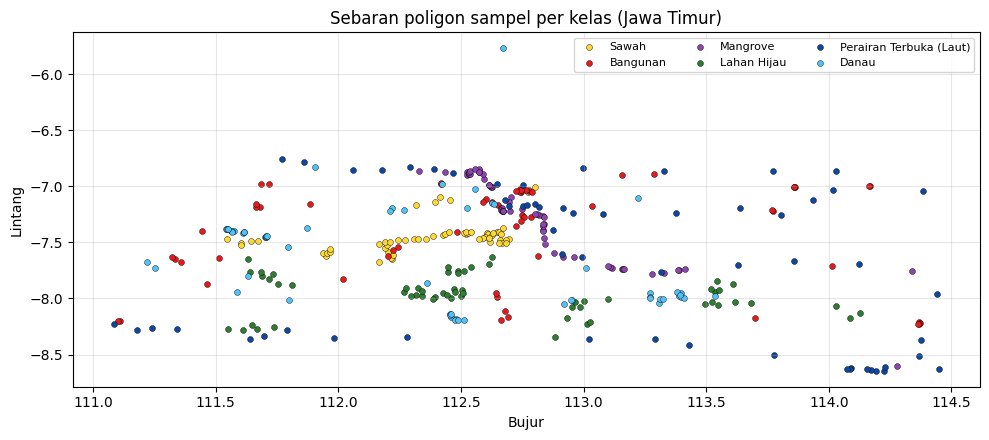

In [97]:
# Peta sebaran poligon sampel (titik representatif tiap poligon)
plt.figure(figsize=(10, 4.5))
for k, v in KELAS.items():
    pts = poligon[k].to_crs(32749).geometry.representative_point().to_crs(4326)
    plt.scatter(pts.x, pts.y, s=18, c=v["warna"], edgecolor="k", linewidth=.3, label=v["nama"])
plt.xlabel("Bujur"); plt.ylabel("Lintang"); plt.grid(alpha=.3)
plt.title("Sebaran poligon sampel per kelas (Jawa Timur)")
plt.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

### 2.3 Pengambilan Citra Sentinel-2 dan Statistik Zonal per Poligon
**Mengapa poligon, bukan piksel?** Tiap kelas memiliki jumlah poligon sama (60), sedangkan jumlah piksel per poligon sangat berbeda (laut/lahan hijau jauh lebih luas dari bangunan). Jika semua piksel dipakai, kelas luas mendominasi dan piksel bertetangga saling berkorelasi (kebocoran data antara training dan testing). Dengan **satu poligon = satu sampel**:

* kelas **seimbang** (60 : 60 : 60 : 60 : 60 : 60),
* tidak ada kebocoran antar-piksel satu poligon,
* nilai **median** tahan terhadap piksel pencilan (bayangan awan, tepi poligon, kapal, dsb.).

Langkah di server Copernicus (*evalscript*): (1) filter periode tanggal dan awan per scene, (2) masking awan memakai band **SCL** (buang kelas 3, 8, 9, 10, 11), (3) **komposit median** per piksel dan per band, (4) seluruh band disampel ke satu grid. Langkah di Python: unduh grid yang menutupi *bounding box* poligon (resolusi 10 m, otomatis dilonggarkan untuk poligon besar agar maksimal `MAKS_PX_POLIGON` piksel per sisi), tentukan piksel yang **berada di dalam poligon**, lalu hitung **median** tiap band.

In [98]:
BAND_ASLI = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
INDEKS    = ["NDVI", "NDWI", "MNDWI", "NDBI", "NDRE", "EVI", "SAVI", "BSI"]
FITUR_SEMUA = BAND_ASLI + INDEKS

_cache = {}
def buat_config():
    if "cfg" not in _cache:
        cfg = SHConfig()
        def rahasia(nama):
            try:
                from google.colab import userdata          # Colab: ikon kunci di sidebar kiri (Secrets)
                return userdata.get(nama)
            except Exception:
                return os.environ.get(nama)
        cfg.sh_client_id = rahasia("CDSE_CLIENT_ID") or input("Client ID : ")
        cfg.sh_client_secret = rahasia("CDSE_CLIENT_SECRET") or getpass.getpass("Client Secret : ")
        cfg.sh_base_url = "https://sh.dataspace.copernicus.eu"
        cfg.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
        _cache["cfg"] = cfg
        try:
            _cache["data"] = DataCollection.SENTINEL2_L2A.define_from("s2l2a_cdse", service_url=cfg.sh_base_url)
        except Exception:
            _cache["data"] = [c for c in DataCollection.get_available_collections() if c.name == "s2l2a_cdse"][0]
    return _cache["cfg"], _cache["data"]

EVALSCRIPT_TEMPLATE = """//VERSION=3
const HANYA_2A = __HANYA_2A__;
function setup() {
  return {
    input: [{ bands: ["B02","B03","B04","B05","B06","B07","B08","B8A","B11","B12","SCL","dataMask"] }],
    output: { bands: 10, sampleType: "FLOAT32" },
    mosaicking: "ORBIT"
  };
}
function median(a) {
  a.sort(function(x, y) { return x - y; });
  var m = Math.floor(a.length / 2);
  return a.length % 2 ? a[m] : (a[m - 1] + a[m]) / 2;
}
function evaluatePixel(samples, scenes) {
  var nama = ["B02","B03","B04","B05","B06","B07","B08","B8A","B11","B12"];
  var nilai = nama.map(function() { return []; });
  for (var i = 0; i < samples.length; i++) {
    var s = samples[i];
    if (s.dataMask === 0) continue;
    var c = s.SCL;
    if (c === 3 || c === 8 || c === 9 || c === 10 || c === 11) continue;
    if (HANYA_2A) {
      var pid = scenes.orbits[i].tiles[0].productId;
      if (pid.indexOf("S2A") !== 0) continue;
    }
    for (var k = 0; k < nama.length; k++) nilai[k].push(s[nama[k]]);
  }
  if (nilai[0].length === 0) return nama.map(function() { return NaN; });
  return nilai.map(median);
}
"""
EVALSCRIPT = EVALSCRIPT_TEMPLATE.replace("__HANYA_2A__", "true" if HANYA_SENTINEL_2A else "false")

def ambil_median(bbox, ukuran):
    """Komposit median 10 band untuk bbox dan ukuran (lebar, tinggi) piksel. Hasil: (tinggi, lebar, 10)."""
    cfg, data = buat_config()
    req = SentinelHubRequest(
        evalscript=EVALSCRIPT,
        input_data=[SentinelHubRequest.input_data(
            data_collection=data, time_interval=(TANGGAL_MULAI, TANGGAL_AKHIR),
            maxcc=MAX_CLOUD / 100)],
        responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
        bbox=bbox, size=ukuran, config=cfg)
    return np.asarray(req.get_data()[0], dtype=np.float32)

def tambah_indeks(d):
    """Hitung 8 indeks spektral dari kolom band reflektansi (0-1)."""
    d = d.copy(); e = 1e-9
    nd = lambda a, b: (a - b) / (a + b + e)
    d["NDVI"]  = nd(d["B8"], d["B4"])
    d["NDWI"]  = nd(d["B3"], d["B8"])
    d["MNDWI"] = nd(d["B3"], d["B11"])
    d["NDBI"]  = nd(d["B11"], d["B8"])
    d["NDRE"]  = nd(d["B8"], d["B5"])
    d["EVI"]   = 2.5 * (d["B8"] - d["B4"]) / (d["B8"] + 6 * d["B4"] - 7.5 * d["B2"] + 1)
    d["SAVI"]  = 1.5 * (d["B8"] - d["B4"]) / (d["B8"] + d["B4"] + 0.5)
    d["BSI"]   = (((d["B11"] + d["B4"]) - (d["B8"] + d["B2"])) /
                  ((d["B11"] + d["B4"]) + (d["B8"] + d["B2"]) + e))
    return d
print("Jumlah fitur:", len(FITUR_SEMUA), FITUR_SEMUA)

Jumlah fitur: 18 ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NDRE', 'EVI', 'SAVI', 'BSI']


### Fungsi statistik zonal
Untuk tiap poligon: unduh grid → tandai piksel yang pusatnya berada di dalam poligon (`shapely.contains_xy`) → ambil **median** tiap band dari piksel valid. Jika poligon sangat kecil dan tidak ada pusat piksel di dalamnya, dipakai piksel yang memuat titik representatif poligon.

In [99]:
def ekstrak_poligon(geom, maks_px=MAKS_PX_POLIGON):
    minx, miny, maxx, maxy = geom.bounds
    lat0 = (miny + maxy) / 2
    w_m = max((maxx - minx) * 111320 * math.cos(math.radians(lat0)), 1.0)
    h_m = max((maxy - miny) * 111320, 1.0)
    res = max(10.0, max(w_m, h_m) / maks_px)              # meter per piksel (min. 10 m)
    W, H = max(1, int(round(w_m / res))), max(1, int(round(h_m / res)))
    arr = ambil_median(BBox([minx, miny, maxx, maxy], crs=CRS.WGS84), (W, H))   # (H, W, 10)
    xs = minx + (np.arange(W) + 0.5) * (maxx - minx) / W
    ys = maxy - (np.arange(H) + 0.5) * (maxy - miny) / H
    X, Y = np.meshgrid(xs, ys)
    m = contains_xy(geom, X, Y)
    if m.sum() == 0:                                       # poligon sangat kecil
        rp = geom.representative_point()
        m = np.zeros((H, W), bool)
        m[min(H - 1, int((maxy - rp.y) / (maxy - miny) * H)), min(W - 1, int((rp.x - minx) / (maxx - minx) * W))] = True
    px = arr[m]; px = px[~np.isnan(px).any(axis=1)]        # piksel valid di dalam poligon
    if len(px) == 0:
        return [np.nan] * len(BAND_ASLI), 0
    return list(np.median(px, axis=0)), int(len(px))

def bangun_dataset():
    baris, total = [], sum(len(g) for g in poligon.values()); n = 0
    for k, v in KELAS.items():
        g = poligon[k]
        rp = g.to_crs(32749).geometry.representative_point().to_crs(4326)
        luas_ha = (g.to_crs(32749).area / 1e4).values
        for i, geom in enumerate(g.geometry):
            n += 1; nilai, npx = [np.nan] * len(BAND_ASLI), 0
            for percobaan in range(3):
                try:
                    nilai, npx = ekstrak_poligon(geom); break
                except Exception as e:
                    if percobaan == 2: print(f"\nGagal {v['nama']} #{i}: {str(e)[:150]}")
                    time.sleep(3)
            baris.append({"kelas_id": k, "kelas": v["nama"], "poligon_id": i,
                          "lon": rp.iloc[i].x, "lat": rp.iloc[i].y, "luas_ha": luas_ha[i],
                          "n_piksel": npx, **dict(zip(BAND_ASLI, nilai))})
            print(f"\rPoligon {n}/{total}", end="")
    print()
    return tambah_indeks(pd.DataFrame(baris))

if os.path.exists(CSV_DATASET) and not ULANGI_EKSTRAKSI:
    df = pd.read_csv(CSV_DATASET); print("Dataset dimuat dari", CSV_DATASET)
else:
    df = bangun_dataset(); df.to_csv(CSV_DATASET, index=False)
    print("Dataset diekstrak dari Copernicus dan disimpan ke", CSV_DATASET)

df = df.replace([np.inf, -np.inf], np.nan)
sebelum = len(df)
df = df.dropna(subset=FITUR_SEMUA).reset_index(drop=True)
print(f"Poligon awal: {sebelum} | valid: {len(df)} | dibuang (selalu awan/nodata): {sebelum - len(df)}")
display(df.head())
display(df.groupby("kelas")["n_piksel"].describe().reindex(NAMA_KELAS).round(0))

Dataset dimuat dari /content/drive/MyDrive/UTS_LULC_Jatim/dataset_polygon_sentinel2_jatim.csv
Poligon awal: 360 | valid: 360 | dibuang (selalu awan/nodata): 0


,kelas_id,kelas,poligon_id,lon,lat,luas_ha,n_piksel,B2,B3,B4,...,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDRE,EVI,SAVI,BSI
0,1,Sawah,0,111.643607,-7.489635,713.480095,5795,0.0413,0.06220,0.0456,...,0.1512,0.07305,0.702738,-0.615337,-0.417057,-0.266731,0.468447,0.439982,0.400843,-0.211696
1,1,Sawah,1,111.603837,-7.508273,599.616182,4312,0.0416,0.06105,0.0438,...,0.1545,0.07465,0.703954,-0.610091,-0.433542,-0.240039,0.456594,0.432912,0.392574,-0.193902
2,1,Sawah,2,111.602931,-7.527199,512.319938,3647,0.0504,0.07200,0.0600,...,0.1527,0.07675,0.586990,-0.524046,-0.359146,-0.203131,0.360378,0.351635,0.323604,-0.138256
3,1,Sawah,3,111.547185,-7.472045,1192.756568,5227,0.0476,0.06930,0.0550,...,0.1480,0.07270,0.598833,-0.519584,-0.362172,-0.193900,0.335364,0.344321,0.318135,-0.135802
4,1,Sawah,4,111.948702,-7.619009,522.239957,4247,0.0458,0.07070,0.0579,...,0.1901,0.09540,0.664542,-0.605028,-0.457822,-0.203603,0.426869,0.444161,0.407123,-0.146446


,count,mean,std,min,25%,50%,75%,max
kelas,,,,,,,,
Sawah,60.0,4908.0,1825.0,1829.0,3238.0,4982.0,6179.0,9157.0
Bangunan,60.0,2528.0,2069.0,4.0,917.0,1748.0,4455.0,6814.0
Mangrove,60.0,1392.0,1322.0,121.0,464.0,1055.0,1720.0,6599.0
Lahan Hijau,60.0,8768.0,1331.0,3083.0,8207.0,9090.0,9488.0,11119.0
Perairan Terbuka (Laut),60.0,6540.0,2330.0,977.0,5391.0,6632.0,8036.0,12021.0
Danau,60.0,1972.0,1826.0,53.0,547.0,1372.0,2875.0,9884.0


## 3. Deskripsi Fitur dan Rumusnya
Total **18 fitur**: 10 band reflektansi + 8 indeks spektral turunan. Notasi: $\rho_{B2}$ = reflektansi band B2, dst. Karena unit sampel adalah poligon, setiap fitur adalah **median piksel di dalam poligon**, lalu indeks dihitung dari median band tersebut.

### 3.1 Fitur Band Asli (10 fitur)
Nilai pada produk L2A: $\rho = \dfrac{DN}{10000}$ (rentang 0–1).

| Fitur | Deskripsi | Satuan |
|---|---|---|
| B2 | Reflektansi Biru (492 nm) | 0–1 |
| B3 | Reflektansi Hijau (560 nm) | 0–1 |
| B4 | Reflektansi Merah (665 nm) | 0–1 |
| B5 | Reflektansi Red Edge 1 (704 nm) | 0–1 |
| B6 | Reflektansi Red Edge 2 (740 nm) | 0–1 |
| B7 | Reflektansi Red Edge 3 (783 nm) | 0–1 |
| B8 | Reflektansi NIR (833 nm) | 0–1 |
| B8A | Reflektansi Narrow NIR (865 nm) | 0–1 |
| B11 | Reflektansi SWIR 1 (1614 nm) | 0–1 |
| B12 | Reflektansi SWIR 2 (2202 nm) | 0–1 |

### 3.2 Fitur Indeks Spektral (8 fitur)

| Fitur | Nama lengkap | Rumus | Rentang | Interpretasi |
|---|---|---|---|---|
| NDVI | Normalized Difference Vegetation Index | $\dfrac{\rho_{B8}-\rho_{B4}}{\rho_{B8}+\rho_{B4}}$ | −1 s.d. 1 | Tinggi = vegetasi rapat; rendah/negatif = air, bangunan |
| NDWI | Normalized Difference Water Index (McFeeters) | $\dfrac{\rho_{B3}-\rho_{B8}}{\rho_{B3}+\rho_{B8}}$ | −1 s.d. 1 | Positif = permukaan air |
| MNDWI | Modified NDWI (Xu) | $\dfrac{\rho_{B3}-\rho_{B11}}{\rho_{B3}+\rho_{B11}}$ | −1 s.d. 1 | Memisahkan air dari area terbangun lebih baik |
| NDBI | Normalized Difference Built-up Index | $\dfrac{\rho_{B11}-\rho_{B8}}{\rho_{B11}+\rho_{B8}}$ | −1 s.d. 1 | Tinggi = area terbangun/lahan terbuka |
| NDRE | Normalized Difference Red Edge | $\dfrac{\rho_{B8}-\rho_{B5}}{\rho_{B8}+\rho_{B5}}$ | −1 s.d. 1 | Sensitif terhadap klorofil dan kondisi kanopi |
| EVI | Enhanced Vegetation Index | $2{,}5\cdot\dfrac{\rho_{B8}-\rho_{B4}}{\rho_{B8}+6\rho_{B4}-7{,}5\rho_{B2}+1}$ | ≈ −1 s.d. 1 | Vegetasi dengan koreksi atmosfer/tanah, tidak mudah jenuh |
| SAVI | Soil Adjusted Vegetation Index | $1{,}5\cdot\dfrac{\rho_{B8}-\rho_{B4}}{\rho_{B8}+\rho_{B4}+0{,}5}$ | ≈ −1,5 s.d. 1,5 | Vegetasi dengan koreksi latar tanah (faktor $L=0{,}5$) |
| BSI | Bare Soil Index | $\dfrac{(\rho_{B11}+\rho_{B4})-(\rho_{B8}+\rho_{B2})}{(\rho_{B11}+\rho_{B4})+(\rho_{B8}+\rho_{B2})}$ | −1 s.d. 1 | Tinggi = tanah terbuka/permukaan terbangun |

**Catatan:** indeks vegetasi (NDVI, EVI, SAVI, NDRE) saling berkorelasi tinggi karena memakai band yang sama (dibahas di EDA). NDWI dan MNDWI menolong memisahkan perairan dari daratan. NDMI tidak dipakai karena identik dengan −NDBI (redundan).

## 4. Eksplorasi Data (EDA)
### 4.1 Jumlah Data per Kelas

Jumlah kelas: 6 | Jumlah data (poligon): 360


,jumlah sampel
kelas,
Sawah,60
Bangunan,60
Mangrove,60
Lahan Hijau,60
Perairan Terbuka (Laut),60
Danau,60


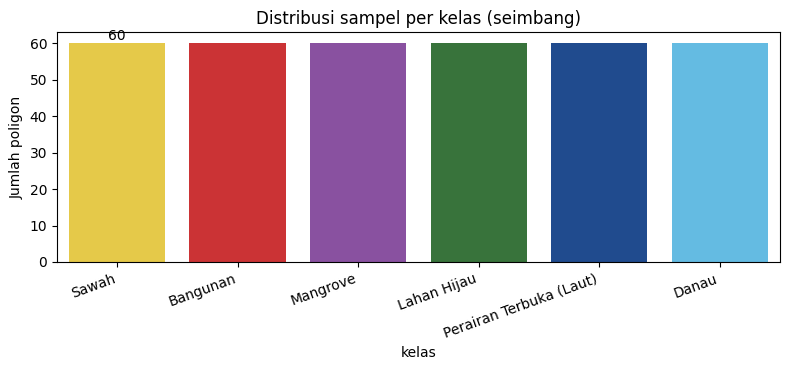

In [100]:
jml = df["kelas"].value_counts().reindex(NAMA_KELAS)
print("Jumlah kelas:", df["kelas"].nunique(), "| Jumlah data (poligon):", len(df))
display(jml.to_frame("jumlah sampel"))
plt.figure(figsize=(8, 3.8))
ax = sns.barplot(x=jml.index, y=jml.values, palette=[WARNA_KELAS[k] for k in jml.index])
ax.bar_label(ax.containers[0]); plt.xticks(rotation=20, ha="right")
plt.ylabel("Jumlah poligon"); plt.title("Distribusi sampel per kelas (seimbang)")
plt.tight_layout(); plt.show()

### 4.2 Statistik Deskriptif

In [101]:
display(df[FITUR_SEMUA].describe().T.round(4))
print("\nRata-rata fitur per kelas:")
display(df.groupby("kelas")[FITUR_SEMUA].mean().reindex(NAMA_KELAS).round(3))

,count,mean,std,min,25%,50%,75%,max
B2,360.0,0.0502,0.0240,0.0159,0.0318,0.0428,0.0617,0.1713
B3,360.0,0.0673,0.0246,0.0242,0.0496,0.0637,0.0806,0.1840
B4,360.0,0.0519,0.0365,0.0114,0.0275,0.0359,0.0647,0.1904
B5,360.0,0.0881,0.0447,0.0092,0.0438,0.0939,0.1140,0.2151
B6,360.0,0.1643,0.1041,0.0000,0.0277,0.2041,0.2453,0.4389
B7,360.0,0.1908,0.1250,0.0000,0.0280,0.2297,0.2937,0.5239
B8,360.0,0.1888,0.1277,0.0000,0.0236,0.2270,0.3006,0.5208
B8A,360.0,0.2039,0.1378,0.0000,0.0248,0.2470,0.3197,0.5515
B11,360.0,0.1265,0.0927,0.0070,0.0198,0.1366,0.1846,0.3622
B12,360.0,0.0794,0.0785,0.0052,0.0164,0.0625,0.0934,0.3252



Rata-rata fitur per kelas:


,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDRE,EVI,SAVI,BSI
kelas,,,,,,,,,,,,,,,,,,
Sawah,0.056,0.075,0.063,0.109,0.210,0.247,0.244,0.266,0.165,0.089,0.585,-0.523,-0.369,-0.192,0.379,0.377,0.335,-0.137
Bangunan,0.087,0.104,0.122,0.155,0.200,0.217,0.210,0.232,0.273,0.238,0.267,-0.339,-0.448,0.130,0.152,0.170,0.158,0.141
Mangrove,0.033,0.061,0.033,0.103,0.262,0.310,0.312,0.335,0.115,0.045,0.799,-0.664,-0.298,-0.465,0.496,0.548,0.491,-0.399
Lahan Hijau,0.029,0.048,0.027,0.086,0.253,0.306,0.312,0.333,0.165,0.075,0.840,-0.731,-0.546,-0.309,0.566,0.565,0.508,-0.280
Perairan Terbuka (Laut),0.062,0.064,0.038,0.035,0.025,0.025,0.021,0.022,0.017,0.014,-0.252,0.476,0.549,-0.136,-0.233,-0.055,-0.044,-0.220
Danau,0.034,0.051,0.029,0.041,0.036,0.039,0.034,0.036,0.025,0.016,-0.218,0.444,0.454,-0.010,-0.332,0.003,-0.002,-0.079


### 4.3 Tanda Tangan Spektral (*Spectral Signature*)
* **Vegetasi** (sawah, lahan hijau, mangrove): pantulan rendah di merah (klorofil menyerap), naik tajam di red edge/NIR, turun di SWIR.
* **Air** (laut, danau): rendah dan menurun ke NIR/SWIR karena air menyerap inframerah.
* **Bangunan**: reflektansi relatif tinggi dan datar, SWIR lebih tinggi daripada vegetasi.

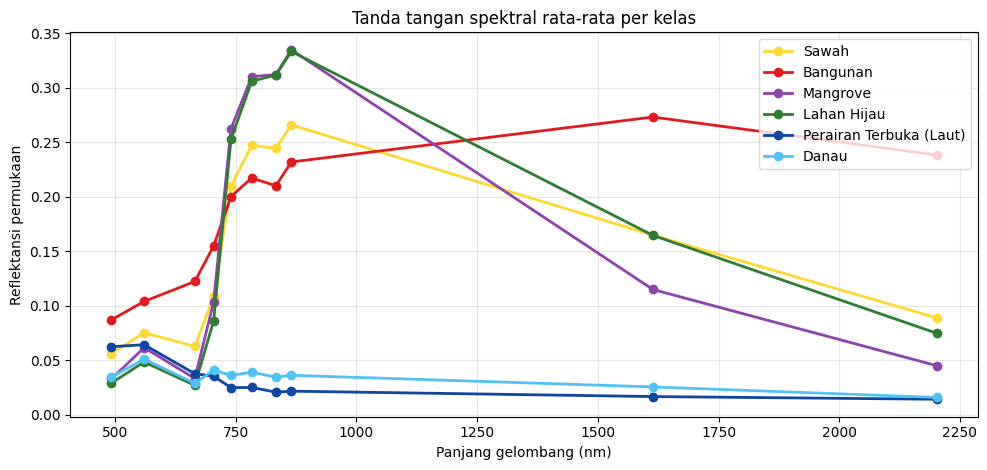

In [102]:
pj = [492, 560, 665, 704, 740, 783, 833, 865, 1614, 2202]
rata = df.groupby("kelas")[BAND_ASLI].mean().reindex(NAMA_KELAS)
plt.figure(figsize=(10, 4.8))
for k in NAMA_KELAS:
    plt.plot(pj, rata.loc[k].values, marker="o", lw=2, label=k, color=WARNA_KELAS[k])
plt.xlabel("Panjang gelombang (nm)"); plt.ylabel("Reflektansi permukaan")
plt.title("Tanda tangan spektral rata-rata per kelas"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.show()

### 4.4 Sebaran Indeks Spektral per Kelas
Boxplot dengan kotak yang tidak tumpang tindih menandakan indeks pembeda yang baik.

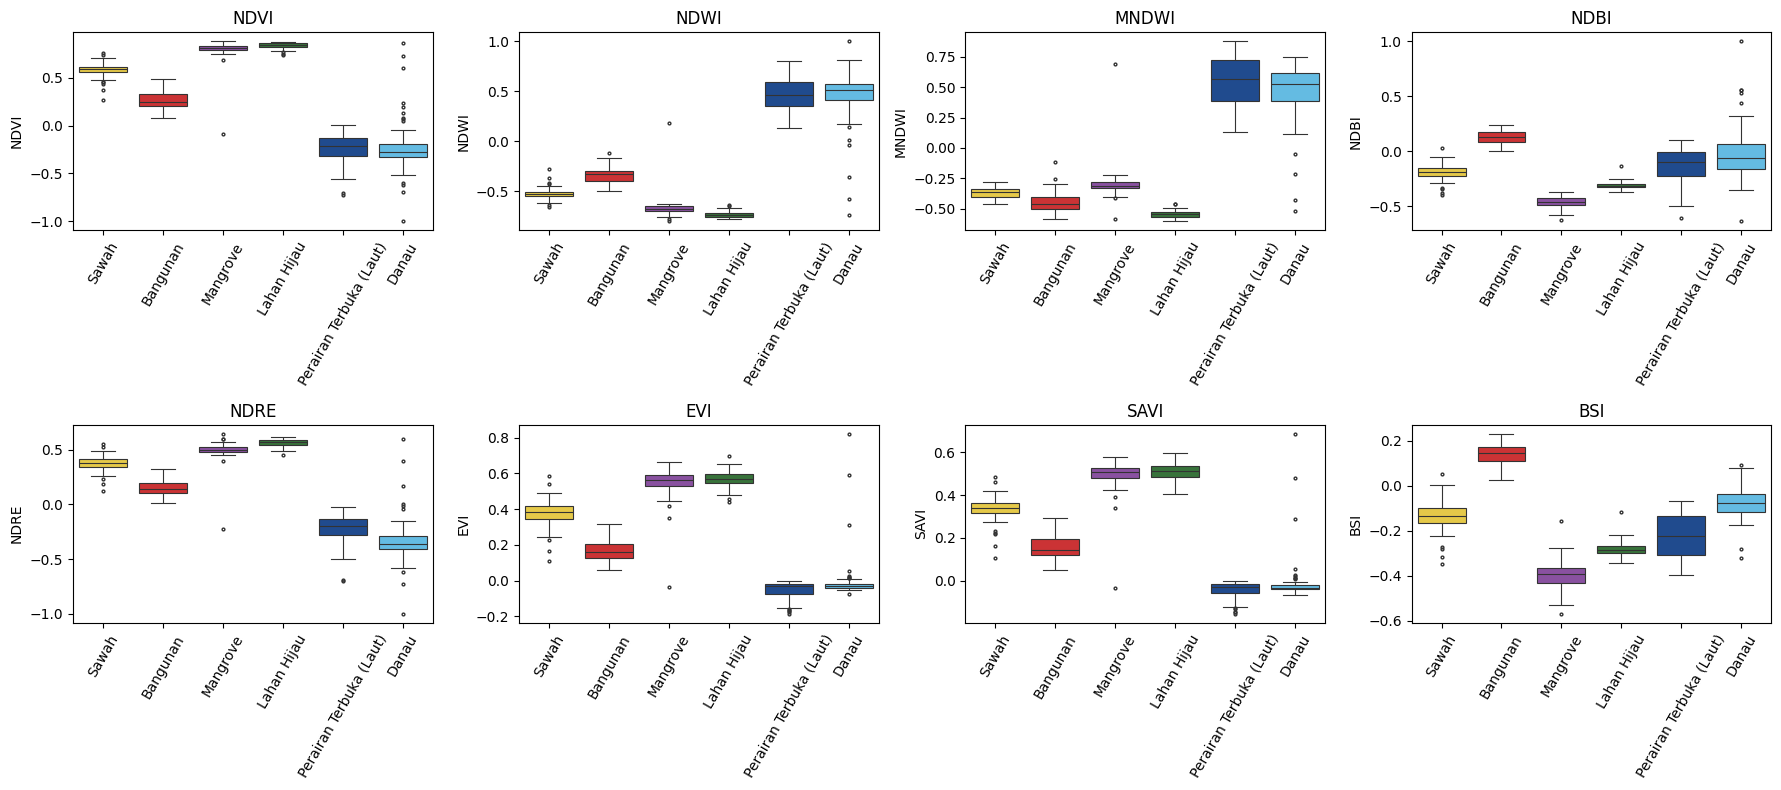

In [103]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), INDEKS):
    sns.boxplot(data=df, x="kelas", y=f, order=NAMA_KELAS, palette=WARNA_KELAS, ax=ax, fliersize=2, linewidth=.8)
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

### 4.5 Korelasi Antar Fitur
Multikolinearitas dan perbedaan skala memengaruhi model berbasis jarak (KNN, SVM) dan model linear, sehingga semua model dalam *pipeline* memakai `StandardScaler`.

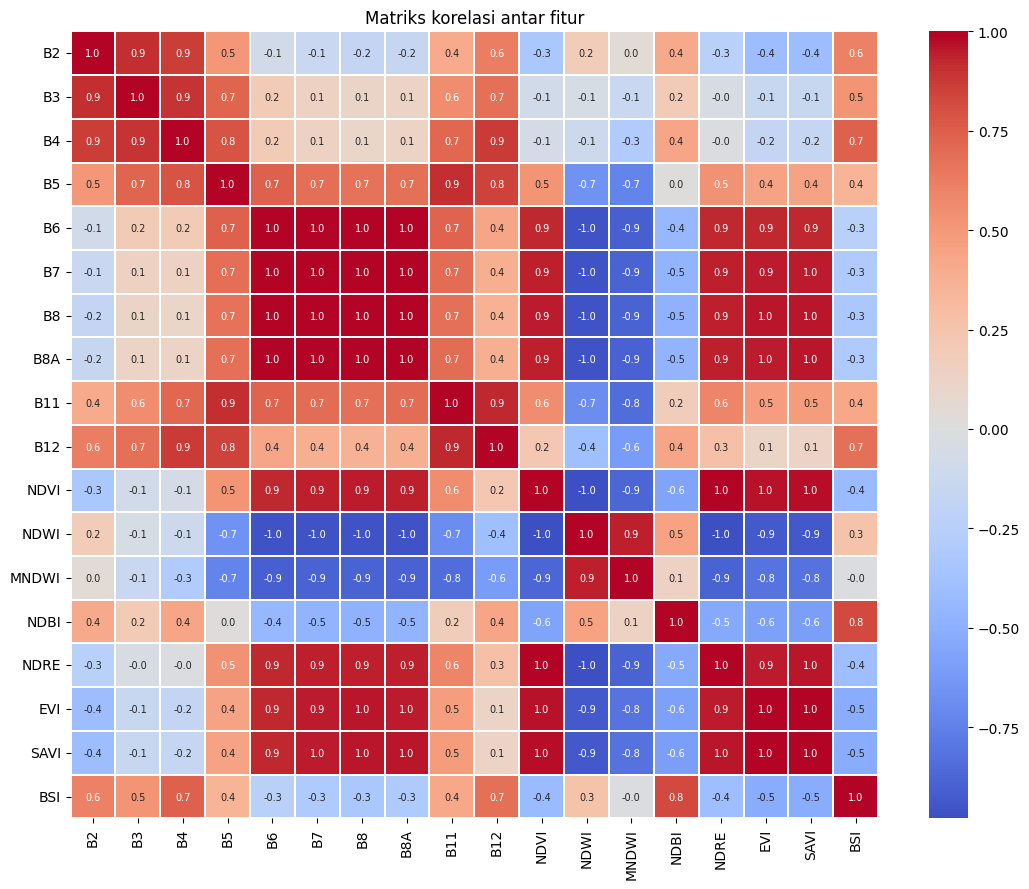

In [104]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[FITUR_SEMUA].corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, linewidths=.3)
plt.title("Matriks korelasi antar fitur"); plt.tight_layout(); plt.show()

## 5. Pembagian Data Training dan Testing
Data dibagi **80% training** dan **20% testing** dengan `stratify=y` agar proporsi 6 kelas sama. Label diubah ke angka 0–5 (kompatibel dengan semua model, termasuk XGBoost/LightGBM). **Data testing tidak disentuh** sampai model final dipilih: seluruh perbandingan dan *tuning* memakai validasi silang **hanya pada data training**.

In [105]:
y_all = df["kelas_id"].astype(int) - 1                  # 0..5
X_all = df[FITUR_SEMUA]
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=UKURAN_TEST, stratify=y_all, random_state=SEED)

tab_split = pd.DataFrame({"Total": y_all.value_counts(), "Training": y_train.value_counts(),
                          "Testing": y_test.value_counts()}).sort_index()
tab_split.index = NAMA_KELAS
tab_split.loc["TOTAL"] = tab_split.sum()
print(f"Jumlah kelas        : {y_all.nunique()}")
print(f"Jumlah data training: {len(X_train)} ({len(X_train)/len(X_all):.0%})")
print(f"Jumlah data testing : {len(X_test)} ({len(X_test)/len(X_all):.0%})")
display(tab_split.astype(int))

Jumlah kelas        : 6
Jumlah data training: 288 (80%)
Jumlah data testing : 72 (20%)


,Total,Training,Testing
Sawah,60,48,12
Bangunan,60,48,12
Mangrove,60,48,12
Lahan Hijau,60,48,12
Perairan Terbuka (Laut),60,48,12
Danau,60,48,12
TOTAL,360,288,72


## 6. Perbandingan Model dan Eksperimen
### 6.1 Kandidat Model
Beberapa keluarga algoritma dibandingkan secara adil (preprocessing sama, CV sama):

| Keluarga | Model |
|---|---|
| Berbasis jarak | KNN |
| Kernel | SVM (RBF) |
| Linear | Logistic Regression |
| Probabilistik | Gaussian Naive Bayes |
| Pohon tunggal | Decision Tree |
| *Ensemble* bagging | Random Forest, Extra Trees |
| *Ensemble* boosting | Gradient Boosting, HistGradientBoosting, (opsional) XGBoost, LightGBM |
| Jaringan saraf | MLP |
| Gabungan | Voting Ensemble (RF + ExtraTrees + SVM + HistGB) |

Metrik: akurasi, F1-macro, Kappa Cohen dari **Repeated Stratified 5-Fold CV (5 pengulangan = 25 evaluasi)** pada data training.

In [106]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, VotingClassifier)
from sklearn.neural_network import MLPClassifier

def pipa(clf): return Pipeline([("scaler", StandardScaler()), ("clf", clf)])

MODELS = {
    "KNN":                  pipa(KNeighborsClassifier(n_neighbors=5, weights="distance")),
    "SVM (RBF)":            pipa(SVC(kernel="rbf", C=10, gamma="scale", probability=True, random_state=SEED)),
    "Logistic Regression":  pipa(LogisticRegression(C=10, max_iter=5000, random_state=SEED)),
    "Naive Bayes":          pipa(GaussianNB()),
    "Decision Tree":        pipa(DecisionTreeClassifier(random_state=SEED)),
    "Random Forest":        pipa(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
    "Extra Trees":          pipa(ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting":    pipa(GradientBoostingClassifier(random_state=SEED)),
    "HistGradientBoosting": pipa(HistGradientBoostingClassifier(random_state=SEED)),
    "MLP (Neural Net)":     pipa(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=SEED)),
}
try:
    from xgboost import XGBClassifier
    MODELS["XGBoost"] = pipa(XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4,
                                           eval_metric="mlogloss", random_state=SEED, n_jobs=-1))
except Exception: print("xgboost tidak terpasang, dilewati")
try:
    from lightgbm import LGBMClassifier
    MODELS["LightGBM"] = pipa(LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1))
except Exception: print("lightgbm tidak terpasang, dilewati")
MODELS["Voting Ensemble"] = pipa(VotingClassifier(estimators=[
    ("rf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ("et", ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ("svm", SVC(C=10, probability=True, random_state=SEED)),
    ("hgb", HistGradientBoostingClassifier(random_state=SEED))], voting="soft"))

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
SCORING = {"acc": "accuracy", "f1": "f1_macro", "kappa": make_scorer(cohen_kappa_score)}

hasil = []
for nama, mdl in MODELS.items():
    t0 = time.time()
    r = cross_validate(mdl, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    hasil.append({"Model": nama, "Akurasi CV": r["test_acc"].mean(), "Std": r["test_acc"].std(),
                  "F1 macro CV": r["test_f1"].mean(), "Kappa CV": r["test_kappa"].mean(),
                  "Waktu (s)": time.time() - t0})
    print(f"{nama:<22} akurasi CV = {r['test_acc'].mean():.4f} +/- {r['test_acc'].std():.4f}")
tab_model = pd.DataFrame(hasil).sort_values("Akurasi CV", ascending=False).reset_index(drop=True)
display(tab_model.round(4))

KNN                    akurasi CV = 0.9597 +/- 0.0244
SVM (RBF)              akurasi CV = 0.9792 +/- 0.0139
Logistic Regression    akurasi CV = 0.9708 +/- 0.0212
Naive Bayes            akurasi CV = 0.8639 +/- 0.0278
Decision Tree          akurasi CV = 0.9514 +/- 0.0263
Random Forest          akurasi CV = 0.9653 +/- 0.0214
Extra Trees            akurasi CV = 0.9737 +/- 0.0197
Gradient Boosting      akurasi CV = 0.9527 +/- 0.0269
HistGradientBoosting   akurasi CV = 0.9618 +/- 0.0321
MLP (Neural Net)       akurasi CV = 0.9694 +/- 0.0180
XGBoost                akurasi CV = 0.9500 +/- 0.0341
LightGBM               akurasi CV = 0.9653 +/- 0.0254
Voting Ensemble        akurasi CV = 0.9702 +/- 0.0211


,Model,Akurasi CV,Std,F1 macro CV,Kappa CV,Waktu (s)
0,SVM (RBF),0.9792,0.0139,0.9793,0.9750,0.4457
1,Extra Trees,0.9737,0.0197,0.9737,0.9684,12.5699
2,Logistic Regression,0.9708,0.0212,0.9707,0.9650,0.6028
3,Voting Ensemble,0.9702,0.0211,0.9702,0.9642,38.1871
4,MLP (Neural Net),0.9694,0.0180,0.9694,0.9633,16.7354
5,LightGBM,0.9653,0.0254,0.9652,0.9583,10.5608
6,Random Forest,0.9653,0.0214,0.9653,0.9583,16.9585
7,HistGradientBoosting,0.9618,0.0321,0.9617,0.9542,7.6834
8,KNN,0.9597,0.0244,0.9595,0.9517,2.8968
9,Gradient Boosting,0.9527,0.0269,0.9527,0.9433,60.1444


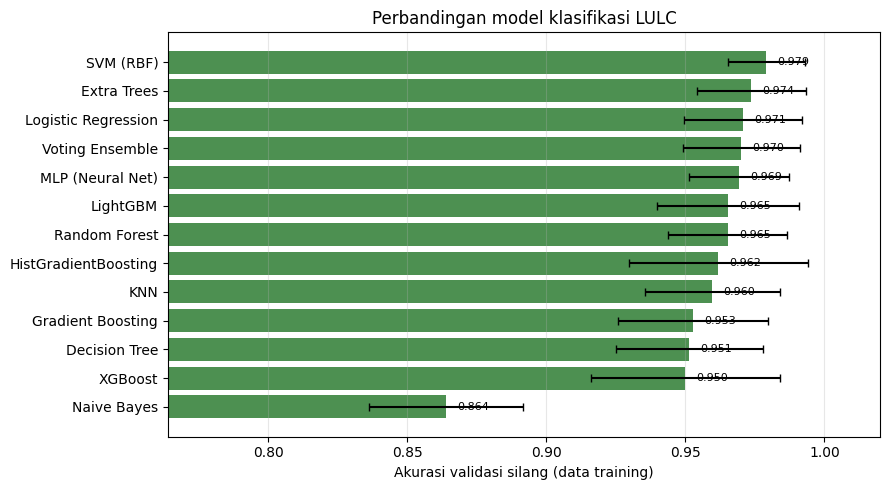

In [107]:
plt.figure(figsize=(9, 5))
t = tab_model.sort_values("Akurasi CV")
plt.barh(t["Model"], t["Akurasi CV"], xerr=t["Std"], color="#2E7D32", alpha=.85, capsize=3)
for i, v in enumerate(t["Akurasi CV"]): plt.text(v + .004, i, f"{v:.3f}", va="center", fontsize=8)
plt.xlim(max(0, t["Akurasi CV"].min() - .1), 1.02)
plt.xlabel("Akurasi validasi silang (data training)"); plt.title("Perbandingan model klasifikasi LULC")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

### 6.2 Tuning *Hyperparameter* (3 Model Teratas)
Tiga model dengan akurasi CV tertinggi di-*tuning* memakai **Grid Search** (Repeated Stratified 5-Fold). Model dengan skor CV tuning tertinggi menjadi **model final**.

In [108]:
GRIDS = {
    "KNN": {"clf__n_neighbors": [3, 5, 7, 9, 11], "clf__weights": ["uniform", "distance"],
            "clf__metric": ["euclidean", "manhattan"]},
    "SVM (RBF)": {"clf__C": [1, 10, 100, 1000], "clf__gamma": ["scale", 0.003, 0.01, 0.03, 0.1]},
    "Logistic Regression": {"clf__C": [0.1, 1, 10, 100, 1000]},
    "Random Forest": {"clf__n_estimators": [200, 500], "clf__max_depth": [None, 10, 20],
                      "clf__max_features": ["sqrt", 0.5]},
    "Extra Trees": {"clf__n_estimators": [200, 500], "clf__max_depth": [None, 10, 20],
                    "clf__max_features": ["sqrt", 0.5]},
    "Gradient Boosting": {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1],
                          "clf__max_depth": [2, 3]},
    "HistGradientBoosting": {"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [None, 5],
                             "clf__max_iter": [100, 200]},
    "MLP (Neural Net)": {"clf__hidden_layer_sizes": [(64,), (64, 32), (128, 64)], "clf__alpha": [1e-4, 1e-2]},
    "XGBoost": {"clf__n_estimators": [200, 400], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [3, 5]},
    "LightGBM": {"clf__n_estimators": [200, 400], "clf__learning_rate": [0.03, 0.05, 0.1], "clf__num_leaves": [7, 15]},
}
cv_tune = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
top3 = tab_model["Model"].head(3).tolist()
tuned = {}
for nama in top3:
    if nama in GRIDS:
        gs = GridSearchCV(MODELS[nama], GRIDS[nama], cv=cv_tune, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
        tuned[nama] = dict(est=gs.best_estimator_, params=gs.best_params_, cv=gs.best_score_)
    else:
        sc = cross_val_score(MODELS[nama], X_train, y_train, cv=cv_tune, scoring="accuracy", n_jobs=-1).mean()
        tuned[nama] = dict(est=clone(MODELS[nama]).fit(X_train, y_train), params={}, cv=sc)
    print(f"{nama:<22} CV tuning = {tuned[nama]['cv']:.4f} | {tuned[nama]['params']}")

tab_tune = pd.DataFrame([{"Model": n, "Akurasi CV (tuned)": v["cv"], "Parameter terbaik": str(v["params"])}
                         for n, v in tuned.items()]).sort_values("Akurasi CV (tuned)", ascending=False).reset_index(drop=True)
display(tab_tune)
MODEL_FINAL_NAMA = tab_tune.loc[0, "Model"]
PARAM_FINAL = tuned[MODEL_FINAL_NAMA]["params"]
print("\nModel final terpilih:", MODEL_FINAL_NAMA)

SVM (RBF)              CV tuning = 0.9792 | {'clf__C': 10, 'clf__gamma': 'scale'}
Extra Trees            CV tuning = 0.9757 | {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__n_estimators': 200}
Logistic Regression    CV tuning = 0.9734 | {'clf__C': 10}


,Model,Akurasi CV (tuned),Parameter terbaik
0,SVM (RBF),0.979169,"{'clf__C': 10, 'clf__gamma': 'scale'}"
1,Extra Trees,0.975741,"{'clf__max_depth': None, 'clf__max_features': ..."
2,Logistic Regression,0.973382,{'clf__C': 10}



Model final terpilih: SVM (RBF)


### 6.3 Evaluasi Model Final pada Data Testing
Evaluasi akhir pada **72 data testing** yang belum pernah dipakai untuk memilih model. Metrik: akurasi, presisi, *recall*, F1-score, Kappa, dan *confusion matrix*.

* Akurasi = $\dfrac{TP+TN}{Total}$ &nbsp;|&nbsp; Presisi = $\dfrac{TP}{TP+FP}$ &nbsp;|&nbsp; Recall = $\dfrac{TP}{TP+FN}$ &nbsp;|&nbsp; F1 = $2\dfrac{P\cdot R}{P+R}$
* Kappa Cohen mengukur kesepakatan di atas peluang acak ($>0{,}8$ sangat baik).

Model final : SVM (RBF)
Akurasi testing: 0.9861 | Kappa: 0.9833 | F1 macro: 0.9861

                         precision    recall  f1-score   support

                  Sawah       0.92      1.00      0.96        12
               Bangunan       1.00      1.00      1.00        12
               Mangrove       1.00      1.00      1.00        12
            Lahan Hijau       1.00      1.00      1.00        12
Perairan Terbuka (Laut)       1.00      1.00      1.00        12
                  Danau       1.00      0.92      0.96        12

               accuracy                           0.99        72
              macro avg       0.99      0.99      0.99        72
           weighted avg       0.99      0.99      0.99        72



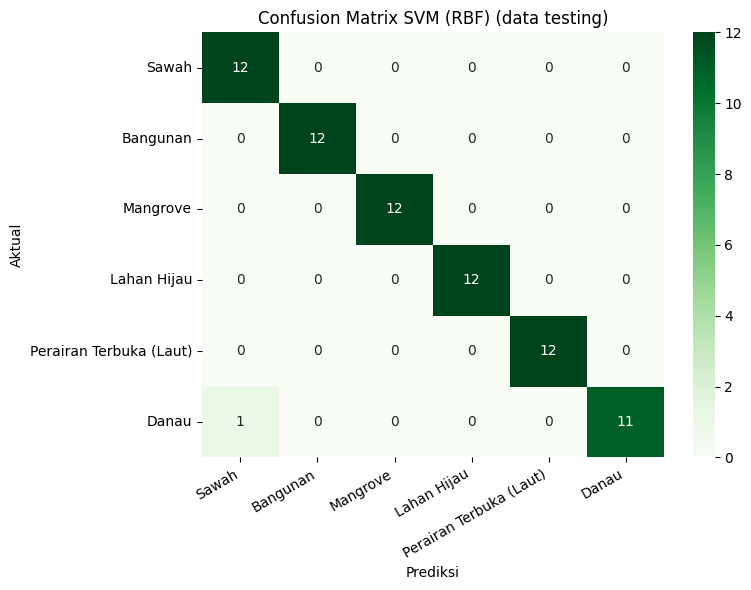

,Model,Akurasi testing,F1 macro,Kappa
0,SVM (RBF),0.9861,0.9861,0.9833
1,Logistic Regression,0.9861,0.9861,0.9833
2,MLP (Neural Net),0.9861,0.9861,0.9833
3,Extra Trees,0.9722,0.9715,0.9667
4,KNN,0.9722,0.9722,0.9667
5,Voting Ensemble,0.9444,0.9428,0.9333
6,LightGBM,0.9444,0.9428,0.9333
7,HistGradientBoosting,0.9444,0.9428,0.9333
8,Random Forest,0.9444,0.9428,0.9333
9,Gradient Boosting,0.9306,0.9291,0.9167


In [109]:
model_final = tuned[MODEL_FINAL_NAMA]["est"]          # sudah dilatih pada X_train
pred_test = model_final.predict(X_test)
AKURASI_FINAL = accuracy_score(y_test, pred_test)
KAPPA_FINAL   = cohen_kappa_score(y_test, pred_test)
F1_FINAL      = f1_score(y_test, pred_test, average="macro")
print(f"Model final : {MODEL_FINAL_NAMA}")
print(f"Akurasi testing: {AKURASI_FINAL:.4f} | Kappa: {KAPPA_FINAL:.4f} | F1 macro: {F1_FINAL:.4f}\n")
lap = classification_report(y_test, pred_test, target_names=NAMA_KELAS, zero_division=0, output_dict=True)
print(classification_report(y_test, pred_test, target_names=NAMA_KELAS, zero_division=0))

cm = confusion_matrix(y_test, pred_test)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=NAMA_KELAS, yticklabels=NAMA_KELAS)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title(f"Confusion Matrix {MODEL_FINAL_NAMA} (data testing)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

# Perbandingan semua model pada data testing (dilatih ulang pada X_train)
uji = []
for nama, mdl in MODELS.items():
    p = clone(mdl).fit(X_train, y_train).predict(X_test)
    uji.append({"Model": nama, "Akurasi testing": accuracy_score(y_test, p),
                "F1 macro": f1_score(y_test, p, average="macro"), "Kappa": cohen_kappa_score(y_test, p)})
tab_uji = pd.DataFrame(uji).sort_values("Akurasi testing", ascending=False).reset_index(drop=True)
display(tab_uji.round(4))

### Fitur Paling Berpengaruh (*Permutation Importance*)

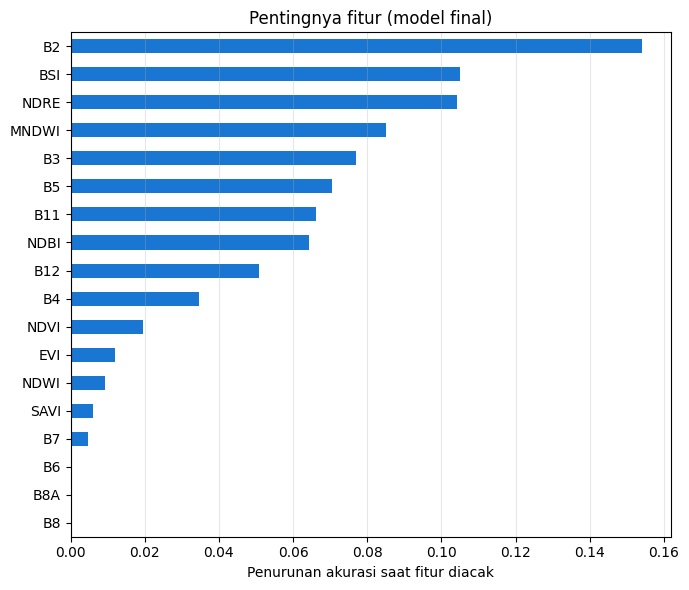

In [110]:
pi = permutation_importance(model_final, X_test, y_test, n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FITUR_SEMUA).sort_values()
plt.figure(figsize=(7, 6)); imp.plot.barh(color="#1976D2")
plt.xlabel("Penurunan akurasi saat fitur diacak"); plt.title("Pentingnya fitur (model final)")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

### 6.4 Eksperimen Kombinasi Fitur
Apakah indeks spektral meningkatkan kinerja dibanding band mentah saja? Model final dievaluasi ulang pada beberapa skenario fitur (CV berulang pada data training).

In [111]:
skenario_fitur = {
    "A. 4 band 10 m (B2,B3,B4,B8)": ["B2", "B3", "B4", "B8"],
    "B. 10 band Sentinel-2": BAND_ASLI,
    "C. 8 indeks spektral": INDEKS,
    "D. Indeks pilihan (NDVI,MNDWI,NDBI,BSI)": ["NDVI", "MNDWI", "NDBI", "BSI"],
    "E. Band + indeks (18 fitur)": FITUR_SEMUA,
}
rows = []
for nama, cols in skenario_fitur.items():
    s = cross_val_score(clone(model_final), X_train[cols], y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    f = cross_val_score(clone(model_final), X_train[cols], y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    rows.append({"Skenario": nama, "Jumlah fitur": len(cols), "Akurasi CV": s.mean(), "Std": s.std(), "F1 macro CV": f.mean()})
tab_fitur = pd.DataFrame(rows).sort_values("Akurasi CV", ascending=False).reset_index(drop=True)
display(tab_fitur.round(4))
FITUR_FINAL_NAMA = tab_fitur.loc[0, "Skenario"]; FITUR_FINAL = skenario_fitur[FITUR_FINAL_NAMA]
print("Skenario fitur terbaik:", FITUR_FINAL_NAMA)

,Skenario,Jumlah fitur,Akurasi CV,Std,F1 macro CV
0,B. 10 band Sentinel-2,10,0.9819,0.0159,0.9822
1,E. Band + indeks (18 fitur),18,0.9792,0.0139,0.9793
2,C. 8 indeks spektral,8,0.9632,0.0287,0.9629
3,"D. Indeks pilihan (NDVI,MNDWI,NDBI,BSI)",4,0.9507,0.0262,0.9505
4,"A. 4 band 10 m (B2,B3,B4,B8)",4,0.9416,0.0219,0.9415


Skenario fitur terbaik: B. 10 band Sentinel-2


### 6.5 Eksperimen Rasio Training : Testing
Setiap rasio diulang 20 kali dengan *seed* berbeda (model final, fitur skenario terbaik).

In [112]:
rows = []
for ts in [0.10, 0.20, 0.30, 0.40]:
    sk = []
    for r in range(20):
        a, b, c, d = train_test_split(X_all[FITUR_FINAL], y_all, test_size=ts, stratify=y_all, random_state=SEED + r)
        sk.append(accuracy_score(d, clone(model_final).fit(a, c).predict(b)))
    rows.append({"Rasio train:test": f"{int((1-ts)*100)}:{int(ts*100)}", "Akurasi rata-rata": np.mean(sk), "Std": np.std(sk)})
tab_rasio = pd.DataFrame(rows); display(tab_rasio.round(4))

,Rasio train:test,Akurasi rata-rata,Std
0,90:10,0.9875,0.0186
1,80:20,0.9861,0.0124
2,70:30,0.9843,0.0110
3,60:40,0.9812,0.0106


### 6.6 Model Final: Latih Ulang dan Simpan
Agar peta memakai informasi sebanyak mungkin, model final (algoritma + *hyperparameter* terbaik + fitur terbaik) dilatih ulang pada **seluruh 360 poligon**. Angka akurasi yang dilaporkan tetap berasal dari data testing/CV di atas.

In [113]:
model_peta = clone(model_final).fit(X_all[FITUR_FINAL], y_all)   # fitur terbaik
# Jika fitur terbaik berbeda dari 18 fitur, evaluasi ulang cepat pada data testing agar angka laporan konsisten
mdl_cek = clone(model_final).fit(X_train[FITUR_FINAL], y_train)
pr = mdl_cek.predict(X_test[FITUR_FINAL])
AKURASI_FINAL = accuracy_score(y_test, pr); KAPPA_FINAL = cohen_kappa_score(y_test, pr)
F1_FINAL = f1_score(y_test, pr, average="macro")
cm = confusion_matrix(y_test, pr); lap = classification_report(y_test, pr, target_names=NAMA_KELAS, zero_division=0, output_dict=True)
print(f"Model: {MODEL_FINAL_NAMA} | fitur: {FITUR_FINAL_NAMA}")
print(f"Akurasi testing: {AKURASI_FINAL:.4f} | Kappa: {KAPPA_FINAL:.4f} | F1 macro: {F1_FINAL:.4f}")
joblib.dump(model_peta, f"{OUT_DIR}/model_terbaik.joblib")

Model: SVM (RBF) | fitur: B. 10 band Sentinel-2
Akurasi testing: 0.9861 | Kappa: 0.9833 | F1 macro: 0.9861


['/content/drive/MyDrive/UTS_LULC_Jatim/app_data/model_terbaik.joblib']

## 7. Prediksi Raster dan Peta Hasil Klasifikasi
### 7.1 Prediksi Piksel pada Area Studi
Model final memprediksi seluruh piksel Jawa Timur. Area dibagi menjadi ubin (*tile*) agar hemat memori dan permintaan ke Copernicus stabil. Progres disimpan sehingga proses dapat dilanjutkan bila terputus.

> **Catatan:** kotak AOI mencakup sebagian Bali, Jawa Tengah, dan Madura selain Jawa Timur. Untuk batas administratif yang tepat, hasil dapat dipotong dengan shapefile batas provinsi (opsional, lihat *Keterbatasan*).

In [114]:
JATIM = [111.0, -8.85, 114.65, -6.75]      # [barat, selatan, timur, utara]
AOI = JATIM
SKALA_PETA = 120                            # meter/piksel (60 = lebih detail tetapi lebih lama)
TILE_PX = 500

def hex_ke_rgb(h):
    h = h.lstrip("#"); return [int(h[i:i+2], 16) for i in (0, 2, 4)]

def klasifikasi_aoi(aoi, skala, tile_px, model, fitur):
    barat, selatan, timur, utara = aoi
    dx = skala / 111320.0
    W = int(math.ceil((timur - barat) / dx)); H = int(math.ceil((utara - selatan) / dx))
    n_tile = math.ceil(H / tile_px) * math.ceil(W / tile_px)
    print(f"Raster {W} x {H} piksel ({W*H:,}), {n_tile} ubin")
    label = np.full((H, W), -1, dtype=np.int8)
    if os.path.exists(FILE_PETA):                       # lanjutkan hasil sebelumnya
        try:
            z = np.load(FILE_PETA, allow_pickle=True)
            if z["label"].shape == (H, W): label = z["label"].copy(); print("Melanjutkan raster yang ada")
        except Exception: pass
    n, gagal = 0, []
    for r0 in range(0, H, tile_px):
        for c0 in range(0, W, tile_px):
            r1, c1 = min(r0 + tile_px, H), min(c0 + tile_px, W); n += 1
            if np.mean(label[r0:r1, c0:c1] != -1) > 0.5:
                print(f"\rUbin {n}/{n_tile} (dilewati)   ", end=""); continue
            bbox = BBox([barat + c0*dx, utara - r1*dx, barat + c1*dx, utara - r0*dx], crs=CRS.WGS84)
            arr = None
            for percobaan in range(3):
                try: arr = ambil_median(bbox, (c1 - c0, r1 - r0)); break
                except Exception as e:
                    if percobaan == 2: gagal.append((r0, c0, str(e)[:200])); print(f"\n[Galat ubin {n}] {str(e)[:150]}")
                    time.sleep(10)
            print(f"\rUbin {n}/{n_tile}            ", end="")
            if arr is None: continue
            h, w = arr.shape[:2]
            d = tambah_indeks(pd.DataFrame(arr.reshape(-1, len(BAND_ASLI)), columns=BAND_ASLI))
            d = d.replace([np.inf, -np.inf], np.nan)
            valid = d[FITUR_SEMUA].notna().all(axis=1).values
            kk = np.full(h * w, -1, dtype=np.int8)
            if valid.any(): kk[valid] = model.predict(d.loc[valid, fitur]).astype(np.int8)
            label[r0:r0+h, c0:c0+w] = kk.reshape(h, w)
            np.savez_compressed(FILE_PETA, label=label)
            time.sleep(2)
    print()
    if gagal: print(f"PERINGATAN: {len(gagal)} ubin gagal. Jalankan sel ini lagi untuk melengkapi.")
    return label, [[utara - H*dx, barat], [utara, barat + W*dx]]

label_peta, batas_peta = klasifikasi_aoi(AOI, SKALA_PETA, TILE_PX, model_peta, FITUR_FINAL)
np.savez_compressed(FILE_PETA, label=label_peta)
print("Ukuran raster:", label_peta.shape)

Raster 3386 x 1949 piksel (6,599,314), 28 ubin
Melanjutkan raster yang ada
Ubin 28/28 (dilewati)   
Ukuran raster: (1949, 3386)


### 7.2 Statistik Luas Hasil Klasifikasi

In [115]:
H, W = label_peta.shape
lat_tengah = (AOI[1] + AOI[3]) / 2
luas_piksel_ha = (SKALA_PETA ** 2 * 1.0) / 1e4          # piksel ~ SKALA x SKALA meter (aproksimasi)
jumlah = np.bincount(label_peta[label_peta >= 0].astype(int), minlength=len(NAMA_KELAS))
tab_luas = pd.DataFrame({"Jumlah piksel": jumlah}, index=NAMA_KELAS)
tab_luas["Luas (ha)"] = (tab_luas["Jumlah piksel"] * luas_piksel_ha).round(1)
tab_luas["Persentase (%)"] = (100 * tab_luas["Jumlah piksel"] / tab_luas["Jumlah piksel"].sum()).round(2)
print(f"Piksel tanpa data: {(label_peta < 0).sum():,} dari {label_peta.size:,}")
display(tab_luas)

Piksel tanpa data: 351 dari 6,599,314


,Jumlah piksel,Luas (ha),Persentase (%)
Sawah,1174612,1691441.3,17.80
Bangunan,624494,899271.4,9.46
Mangrove,37218,53593.9,0.56
Lahan Hijau,1704962,2455145.3,25.84
Perairan Terbuka (Laut),2820428,4061416.3,42.74
Danau,237249,341638.6,3.60


### 7.3 Peta Interaktif Folium dengan Latar Google Satellite
Basemap **Google Satellite** (`lyrs=s`), **Google Hybrid** (`lyrs=y`, dengan label), dan **Esri World Imagery** tersedia sebagai pilihan. Di atasnya: hasil klasifikasi (transparansi diatur), poligon sampel per kelas (default disembunyikan), batas studi, dan legenda.

> Tile Google dipakai langsung lewat URL tile (tanpa API key) untuk keperluan akademik. Untuk produksi/komersial gunakan Google Maps Platform resmi sesuai ketentuan layanan.


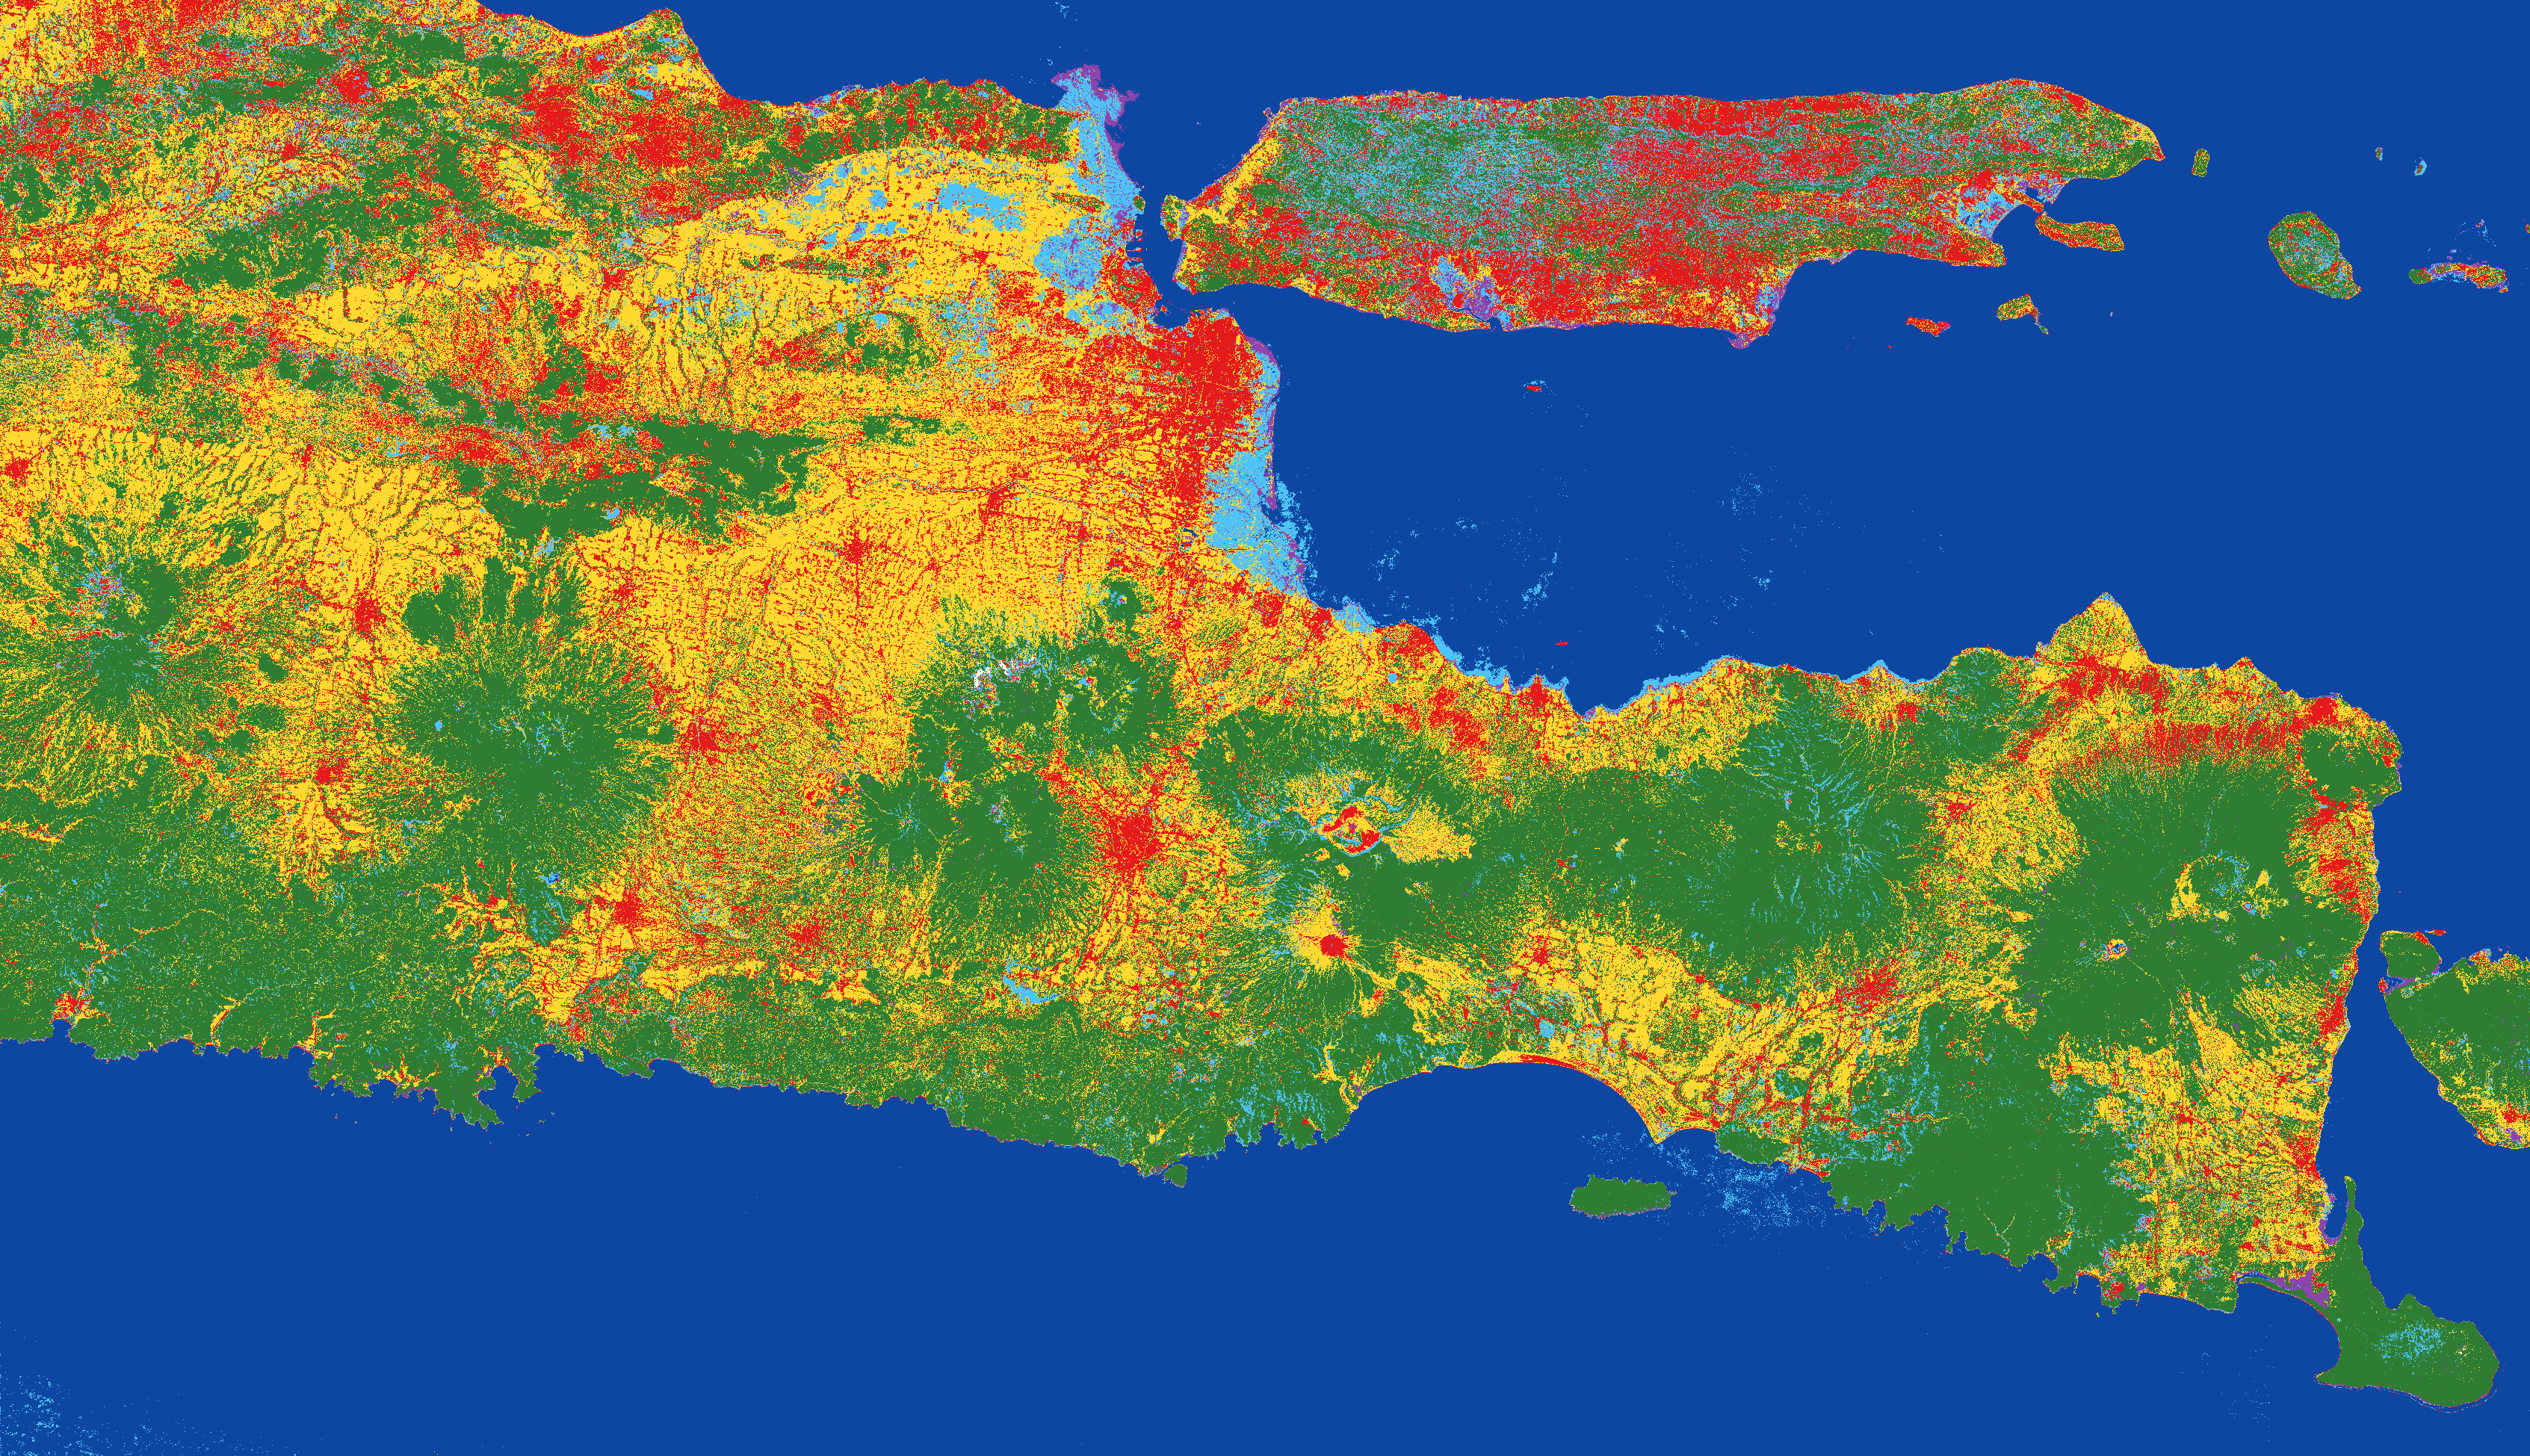

In [116]:
rgba = np.zeros((H, W, 4), dtype=np.uint8)
for idx, nama in enumerate(NAMA_KELAS):
    rgba[label_peta == idx] = hex_ke_rgb(WARNA_KELAS[nama]) + [255]
Image.fromarray(rgba, "RGBA").save(f"{OUT_DIR}/overlay_lulc.png", optimize=True)

pusat = [(AOI[1] + AOI[3]) / 2, (AOI[0] + AOI[2]) / 2]
peta = folium.Map(location=pusat, zoom_start=8, tiles=None, control_scale=True)

folium.TileLayer("https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}", attr="Google Satellite",
                 name="Google Satellite", max_zoom=20, overlay=False, control=True).add_to(peta)
folium.TileLayer("https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}", attr="Google Hybrid",
                 name="Google Hybrid (dengan label)", max_zoom=20, overlay=False, control=True, show=False).add_to(peta)
folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                 attr="Tiles &copy; Esri", name="Esri Satellite", max_zoom=19, overlay=False, control=True, show=False).add_to(peta)

ImageOverlay(image=rgba, bounds=batas_peta, opacity=0.65, name="Hasil Klasifikasi", interactive=False, zindex=5).add_to(peta)

# poligon sampel per kelas (default disembunyikan)
for k, v in KELAS.items():
    g = poligon[k].copy(); g["geometry"] = g.geometry.simplify(0.0008); g["kelas"] = v["nama"]
    folium.GeoJson(g.to_json(), name=f"Poligon sampel: {v['nama']}", show=False,
                   style_function=lambda f, c=v["warna"]: {"color": c, "weight": 1.5, "fillOpacity": .25},
                   tooltip=folium.GeoJsonTooltip(fields=["kelas"])).add_to(peta)

grup_aoi = folium.FeatureGroup(name="Batas area studi")
folium.Rectangle([[AOI[1], AOI[0]], [AOI[3], AOI[2]]], color="white", weight=1.5, fill=False, dash_array="6").add_to(grup_aoi)
grup_aoi.add_to(peta)

item = "".join(f'<div style="margin:2px 0"><span style="display:inline-block;width:14px;height:14px;'
               f'background:{WARNA_KELAS[k]};border:1px solid #333;margin-right:6px;vertical-align:middle"></span>{k}</div>'
               for k in NAMA_KELAS)
legenda = ('<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:10px 12px;'
           f'border:1px solid #888;border-radius:6px;font:13px Arial;"><b>Legenda LULC</b><br>{item}</div>')
peta.get_root().html.add_child(folium.Element(legenda))
folium.LayerControl(collapsed=False).add_to(peta)
peta.fit_bounds([[AOI[1], AOI[0]], [AOI[3], AOI[2]]])

peta

## 8. Ekspor ke Aplikasi Streamlit
### 8.1 Berkas untuk Streamlit
Sel berikut menyimpan semua keluaran ke folder `app_data/` yang dibaca `app.py` (aplikasi Streamlit).

In [117]:
import datetime
tab_model.to_csv(f"{OUT_DIR}/perbandingan_model_cv.csv", index=False)
tab_uji.to_csv(f"{OUT_DIR}/perbandingan_model_test.csv", index=False)
tab_tune.to_csv(f"{OUT_DIR}/tuning_top3.csv", index=False)
tab_fitur.to_csv(f"{OUT_DIR}/eksperimen_fitur.csv", index=False)
tab_rasio.to_csv(f"{OUT_DIR}/eksperimen_rasio.csv", index=False)
tab_luas.reset_index().rename(columns={"index": "Kelas"}).to_csv(f"{OUT_DIR}/luas_kelas.csv", index=False)
pd.DataFrame(lap).T.to_csv(f"{OUT_DIR}/laporan_klasifikasi.csv")
pd.DataFrame(cm, index=NAMA_KELAS, columns=NAMA_KELAS).to_csv(f"{OUT_DIR}/confusion_matrix.csv")
df.to_csv(f"{OUT_DIR}/dataset_polygon.csv", index=False)
np.savez_compressed(f"{OUT_DIR}/label_peta.npz", label=label_peta)

gall = pd.concat([poligon[k].assign(kelas=v["nama"]) for k, v in KELAS.items()], ignore_index=True)
gall["geometry"] = gall.geometry.simplify(0.0008)
gall.to_file(f"{OUT_DIR}/polygon_sampel.geojson", driver="GeoJSON")

meta = dict(model=MODEL_FINAL_NAMA, parameter={k: str(v) for k, v in PARAM_FINAL.items()},
            fitur=FITUR_FINAL, skenario_fitur=FITUR_FINAL_NAMA, nama_kelas=NAMA_KELAS, warna=WARNA_KELAS,
            bounds=batas_peta, aoi=AOI, skala_m=SKALA_PETA, akurasi_test=float(AKURASI_FINAL),
            kappa_test=float(KAPPA_FINAL), f1_macro_test=float(F1_FINAL),
            akurasi_cv=float(tab_tune.loc[0, "Akurasi CV (tuned)"]),
            n_total=int(len(df)), n_train=int(len(X_train)), n_test=int(len(X_test)),
            periode=[TANGGAL_MULAI, TANGGAL_AKHIR], sklearn_version=sklearn.__version__,
            dibuat=datetime.datetime.now().isoformat(timespec="seconds"))
json.dump(meta, open(f"{OUT_DIR}/meta.json", "w"), indent=2, ensure_ascii=False)
print("Isi", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))

Isi /content/drive/MyDrive/UTS_LULC_Jatim/app_data : ['confusion_matrix.csv', 'dataset_polygon.csv', 'eksperimen_fitur.csv', 'eksperimen_rasio.csv', 'label_peta.npz', 'laporan_klasifikasi.csv', 'luas_kelas.csv', 'meta.json', 'model_terbaik.joblib', 'overlay_lulc.png', 'perbandingan_model_cv.csv', 'perbandingan_model_test.csv', 'polygon_sampel.geojson', 'tuning_top3.csv']


### 8.2 Membuat `app.py` dan `requirements.txt` untuk Streamlit
Dua sel berikut menulis aplikasi Streamlit langsung dari notebook ini (tidak perlu file terpisah), lalu sel ketiga mengemas semuanya menjadi satu zip untuk diunduh.

In [118]:
%%writefile app.py
# -*- coding: utf-8 -*-
"""SIG Klasifikasi LULC Jawa Timur (Sentinel-2 + Machine Learning) - aplikasi Streamlit."""
import json, os
import numpy as np, pandas as pd, streamlit as st, joblib, folium
from folium.raster_layers import ImageOverlay
from streamlit_folium import st_folium

DATA = "app_data"
st.set_page_config(page_title="SIG LULC Jawa Timur", page_icon="🗺️", layout="wide")

# ---------------------------------------------------------------- muat data
@st.cache_data
def muat_meta():
    return json.load(open(f"{DATA}/meta.json", encoding="utf-8"))

@st.cache_data
def muat_csv(nama):
    return pd.read_csv(f"{DATA}/{nama}")

@st.cache_data
def muat_label():
    return np.load(f"{DATA}/label_peta.npz")["label"]

@st.cache_resource
def muat_model():
    return joblib.load(f"{DATA}/model_terbaik.joblib")

@st.cache_data
def muat_geojson():
    return json.load(open(f"{DATA}/polygon_sampel.geojson", encoding="utf-8"))

if not os.path.exists(f"{DATA}/meta.json"):
    st.error("Folder `app_data/` belum ada. Jalankan notebook sampai bagian 8 (Ekspor) lalu letakkan hasilnya di samping app.py.")
    st.stop()

meta = muat_meta()
KELAS, WARNA = meta["nama_kelas"], meta["warna"]

def hex_rgb(h):
    h = h.lstrip("#"); return [int(h[i:i + 2], 16) for i in (0, 2, 4)]

def tambah_indeks(d):
    e = 1e-9; nd = lambda a, b: (a - b) / (a + b + e)
    d = d.copy()
    d["NDVI"] = nd(d["B8"], d["B4"]); d["NDWI"] = nd(d["B3"], d["B8"]); d["MNDWI"] = nd(d["B3"], d["B11"])
    d["NDBI"] = nd(d["B11"], d["B8"]); d["NDRE"] = nd(d["B8"], d["B5"])
    d["EVI"] = 2.5 * (d["B8"] - d["B4"]) / (d["B8"] + 6 * d["B4"] - 7.5 * d["B2"] + 1)
    d["SAVI"] = 1.5 * (d["B8"] - d["B4"]) / (d["B8"] + d["B4"] + 0.5)
    d["BSI"] = (((d["B11"] + d["B4"]) - (d["B8"] + d["B2"])) / ((d["B11"] + d["B4"]) + (d["B8"] + d["B2"]) + e))
    return d

BANDS = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]

# ---------------------------------------------------------------- navigasi
st.sidebar.title("🗺️ SIG LULC Jawa Timur")
halaman = st.sidebar.radio("Menu", ["Ringkasan", "Data & EDA", "Perbandingan Model", "Peta LULC",
                                    "Prediksi Manual", "Analisis & Kebijakan"])
st.sidebar.caption(f"Model: **{meta['model']}**  \nAkurasi uji: **{meta['akurasi_test']:.2%}**")

# ---------------------------------------------------------------- halaman
if halaman == "Ringkasan":
    st.title("Klasifikasi Penggunaan & Tutupan Lahan Jawa Timur")
    st.write("Sistem informasi geografis berbasis citra **Sentinel-2 L2A** dan *machine learning* untuk "
             "analisis spasial penggunaan lahan dan kebijakan. Unit sampel: **poligon** (1 poligon = 1 sampel).")
    c = st.columns(5)
    c[0].metric("Jumlah kelas", len(KELAS)); c[1].metric("Total sampel", meta["n_total"])
    c[2].metric("Training / Testing", f"{meta['n_train']} / {meta['n_test']}")
    c[3].metric("Akurasi testing", f"{meta['akurasi_test']:.2%}"); c[4].metric("Kappa", f"{meta['kappa_test']:.3f}")
    st.subheader("Model terpilih")
    st.write(f"**{meta['model']}**  |  fitur: *{meta['skenario_fitur']}* ({len(meta['fitur'])} fitur)  |  "
             f"akurasi CV: {meta['akurasi_cv']:.2%}  |  F1 macro uji: {meta['f1_macro_test']:.3f}")
    if meta["parameter"]:
        st.json(meta["parameter"], expanded=False)
    st.subheader("Kelas LULC")
    st.markdown(" ".join(f'<span style="background:{WARNA[k]};padding:3px 10px;border-radius:12px;'
                         f'color:{"#000" if k in ("Sawah","Danau") else "#fff"};margin-right:6px">{k}</span>' for k in KELAS),
                unsafe_allow_html=True)
    st.caption(f"Periode citra: {meta['periode'][0]} s.d. {meta['periode'][1]}  |  Resolusi peta: {meta['skala_m']} m  |  "
               f"Dibuat: {meta['dibuat']}")

elif halaman == "Data & EDA":
    st.title("Data & Eksplorasi")
    df = muat_csv("dataset_polygon.csv")
    st.subheader("Jumlah sampel per kelas")
    st.bar_chart(df["kelas"].value_counts().reindex(KELAS))
    st.subheader("Tanda tangan spektral rata-rata")
    pj = [492, 560, 665, 704, 740, 783, 833, 865, 1614, 2202]
    rata = df.groupby("kelas")[BANDS].mean().reindex(KELAS)
    sig = rata.T; sig.index = pj; sig.index.name = "Panjang gelombang (nm)"
    st.line_chart(sig)
    st.subheader("Rata-rata fitur per kelas")
    st.dataframe(df.groupby("kelas")[meta["fitur"]].mean().reindex(KELAS).round(3), use_container_width=True)
    with st.expander("Tabel data poligon (hasil statistik zonal)"):
        st.dataframe(df, use_container_width=True)

elif halaman == "Perbandingan Model":
    st.title("Perbandingan Model Klasifikasi")
    cv = muat_csv("perbandingan_model_cv.csv"); te = muat_csv("perbandingan_model_test.csv")
    t1, t2, t3, t4 = st.tabs(["Validasi silang", "Data testing", "Tuning & fitur", "Evaluasi model final"])
    with t1:
        st.caption("Repeated Stratified 5-Fold CV pada data training.")
        st.bar_chart(cv.set_index("Model")["Akurasi CV"])
        st.dataframe(cv.round(4), use_container_width=True)
    with t2:
        st.bar_chart(te.set_index("Model")["Akurasi testing"])
        st.dataframe(te.round(4), use_container_width=True)
    with t3:
        st.write("**Tuning 3 model teratas**"); st.dataframe(muat_csv("tuning_top3.csv"), use_container_width=True)
        st.write("**Eksperimen kombinasi fitur**"); st.dataframe(muat_csv("eksperimen_fitur.csv").round(4), use_container_width=True)
        st.write("**Eksperimen rasio train:test**"); st.dataframe(muat_csv("eksperimen_rasio.csv").round(4), use_container_width=True)
    with t4:
        cm = pd.read_csv(f"{DATA}/confusion_matrix.csv", index_col=0)
        st.write("**Confusion matrix** (baris = aktual, kolom = prediksi)")
        st.dataframe(cm.style.background_gradient(cmap="Greens"), use_container_width=True)
        st.write("**Laporan klasifikasi**")
        st.dataframe(pd.read_csv(f"{DATA}/laporan_klasifikasi.csv", index_col=0).round(3), use_container_width=True)

elif halaman == "Peta LULC":
    st.title("Peta Hasil Klasifikasi")
    c1, c2, c3 = st.columns([2, 1, 1])
    pilih = c1.multiselect("Kelas yang ditampilkan", KELAS, default=KELAS)
    opas = c2.slider("Transparansi hasil", 0.1, 1.0, 0.65, 0.05)
    dasar = c3.selectbox("Peta dasar", ["Google Satellite", "Google Hybrid", "Esri Satellite", "OpenStreetMap"])
    tampil_poly = st.checkbox("Tampilkan poligon sampel", value=False)

    label = muat_label()
    rgba = np.zeros((*label.shape, 4), dtype=np.uint8)
    for i, k in enumerate(KELAS):
        if k in pilih:
            rgba[label == i] = hex_rgb(WARNA[k]) + [255]

    b = meta["bounds"]; aoi = meta["aoi"]
    m = folium.Map(location=[(aoi[1] + aoi[3]) / 2, (aoi[0] + aoi[2]) / 2], zoom_start=8, tiles=None, control_scale=True)
    tiles = {"Google Satellite": ("https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}", "Google"),
             "Google Hybrid": ("https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}", "Google"),
             "Esri Satellite": ("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}", "Esri"),
             "OpenStreetMap": ("https://tile.openstreetmap.org/{z}/{x}/{y}.png", "OpenStreetMap")}
    folium.TileLayer(tiles[dasar][0], attr=tiles[dasar][1], name=dasar, max_zoom=19).add_to(m)
    ImageOverlay(image=rgba, bounds=b, opacity=opas, name="Hasil klasifikasi", zindex=5).add_to(m)
    if tampil_poly:
        for k in pilih:
            fl = [f for f in muat_geojson()["features"] if f["properties"]["kelas"] == k]
            folium.GeoJson({"type": "FeatureCollection", "features": fl}, name=f"Poligon {k}",
                           style_function=lambda f, c=WARNA[k]: {"color": c, "weight": 1.5, "fillOpacity": .25}).add_to(m)
    item = "".join(f'<div style="margin:2px 0"><span style="display:inline-block;width:14px;height:14px;background:{WARNA[k]};'
                   f'border:1px solid #333;margin-right:6px;vertical-align:middle"></span>{k}</div>' for k in KELAS)
    m.get_root().html.add_child(folium.Element(
        '<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:10px 12px;'
        f'border:1px solid #888;border-radius:6px;font:13px Arial;color:#000"><b>Legenda LULC</b><br>{item}</div>'))
    folium.LayerControl(collapsed=True).add_to(m)
    m.fit_bounds([[aoi[1], aoi[0]], [aoi[3], aoi[2]]])
    st_folium(m, height=650, use_container_width=True, returned_objects=[])
    st.caption("Tile Google dipakai untuk keperluan akademik; untuk produksi gunakan Google Maps Platform resmi.")

elif halaman == "Prediksi Manual":
    st.title("Prediksi Kelas dari Nilai Reflektansi")
    st.write("Masukkan reflektansi permukaan (0–1) tiap band; indeks spektral dihitung otomatis.")
    df = muat_csv("dataset_polygon.csv")
    preset = st.selectbox("Isi dengan rata-rata kelas (opsional)", ["-"] + KELAS)
    awal = df[df["kelas"] == preset][BANDS].mean() if preset != "-" else df[BANDS].mean()
    cols = st.columns(5); nilai = {}
    for i, bnd in enumerate(BANDS):
        nilai[bnd] = cols[i % 5].number_input(bnd, 0.0, 1.0, float(round(awal[bnd], 4)), 0.005, format="%.4f", key=f"{bnd}_{preset}")
    x = tambah_indeks(pd.DataFrame([nilai]))[meta["fitur"]]
    model = muat_model()
    pred = int(model.predict(x)[0])
    st.success(f"Prediksi: **{KELAS[pred]}**")
    if hasattr(model, "predict_proba"):
        pr = pd.Series(model.predict_proba(x)[0], index=[KELAS[int(c)] for c in model.classes_]).reindex(KELAS).fillna(0)
        st.bar_chart(pr)
    st.dataframe(tambah_indeks(pd.DataFrame([nilai]))[["NDVI", "NDWI", "MNDWI", "NDBI", "NDRE", "EVI", "SAVI", "BSI"]].round(3))

elif halaman == "Analisis & Kebijakan":
    st.title("Analisis Spasial & Implikasi Kebijakan")
    luas = muat_csv("luas_kelas.csv").set_index("Kelas")
    c1, c2 = st.columns([1, 1])
    c1.dataframe(luas, use_container_width=True)
    c2.bar_chart(luas["Persentase (%)"])
    sawah, bangunan, mangrove = (luas.loc[k, "Luas (ha)"] for k in ("Sawah", "Bangunan", "Mangrove"))
    st.markdown(f"""
* **Ketahanan pangan:** luas sawah terklasifikasi ± **{sawah:,.0f} ha**; rasio sawah : bangunan ≈ **{sawah / max(bangunan, 1):.1f} : 1**.
  Kerangka terkait: UU 41/2009 (LP2B) dan Perpres 59/2019 (pengendalian alih fungsi lahan sawah).
* **Tata ruang:** area terbangun ± **{bangunan:,.0f} ha**; bandingkan dengan RTRW (UU 26/2007) untuk menilai kesesuaian ruang.
* **Ekosistem pesisir:** mangrove ± **{mangrove:,.0f} ha**; Strategi Nasional Pengelolaan Ekosistem Mangrove (Perpres 73/2012).
""")
    st.info("Angka luas bersifat aproksimasi (piksel 120 m, AOI berbentuk kotak sehingga mencakup sebagian wilayah di luar Jawa Timur). "
            "Verifikasi dokumen kebijakan resmi sebelum dikutip pada laporan.")

Overwriting app.py


In [119]:
req = ["streamlit>=1.35", "streamlit-folium>=0.20", "folium>=0.16", "pandas", "numpy", "matplotlib", "joblib",
       f"scikit-learn=={sklearn.__version__}"]          # versi harus sama dengan saat melatih model
if "XGB" in type(model_peta[-1]).__name__:  req.append("xgboost")
if "LGBM" in type(model_peta[-1]).__name__: req.append("lightgbm")
open(os.path.join(BASE, "requirements.txt"), "w").write("\n".join(req) + "\n")
print("requirements.txt:", req)

requirements.txt: ['streamlit>=1.35', 'streamlit-folium>=0.20', 'folium>=0.16', 'pandas', 'numpy', 'matplotlib', 'joblib', 'scikit-learn==1.6.1']


In [120]:
import shutil
paket = os.path.join(BASE, "paket_deploy")
shutil.rmtree(paket, ignore_errors=True); os.makedirs(paket)
shutil.copy("app.py", paket); shutil.copy(os.path.join(BASE, "requirements.txt"), paket)
shutil.copytree(OUT_DIR, os.path.join(paket, "app_data"))
zip_path = shutil.make_archive(os.path.join(BASE, "paket_deploy"), "zip", paket)
print("Paket siap:", zip_path)
if IN_COLAB:
    from google.colab import files; files.download(zip_path)      # unduh ke komputer

Paket siap: /content/drive/MyDrive/UTS_LULC_Jatim/paket_deploy.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Kesimpulan

Penelitian ini mengklasifikasikan penggunaan dan tutupan lahan Jawa Timur ke dalam 6 kelas (sawah, bangunan, mangrove, lahan hijau, perairan terbuka/laut, dan danau) menggunakan citra Sentinel-2 L2A dan 360 poligon sampel yang seimbang (masing-masing 60 poligon per kelas), dengan pembagian 288 data training dan 72 data testing. Setiap poligon diringkas menjadi nilai median spektral, dan skenario fitur terbaik yang dipakai adalah 10 band Sentinel-2. Sebanyak 13 model dibandingkan dengan validasi silang berulang; pada tahap awal peringkat pertama diraih SVM (RBF) dengan akurasi CV 97,92%, dan setelah tuning model final yang terpilih tetap SVM (RBF) dengan akurasi CV 97,92%. Pada data testing, model final mencapai akurasi 98,61%, Kappa 0,983, dan F1 macro 0,986, dengan kelas Danau sebagai kelas dengan F1 terendah (0,96). Eksperimen rasio data menunjukkan hasil terbaik pada pembagian 90:10 (98,75%). Hasil klasifikasi ditampilkan sebagai peta interaktif Folium di atas citra Google Satellite dan dipublikasikan melalui aplikasi Streamlit.